# Appliances Energy Prediction: Prediction, Explanation and Anomaly Review

**student name:** parina roshan sharma

**id:** 25370m55

**Notebook outline**
1. Setup and data loading
2. Exploratory Data Analysis (EDA)
3. PCA
4. Preprocessing and feature engineering
5. Models (baseline, Ridge, Random Forest, LightGBM)
6. AutoML (FLAML)
7. Hyperparameter tuning
8. Evaluation
9. Explainable AI (feature importance, permutation importance, SHAP)
10. Unusual observations (anomalies vs. waste)
11. Extension: short-term forecasting with recent consumption
12. Findings, reflection and presentation script

## 1. Setup and data loading

The project predicts Appliances energy consumption (Wh per 10-minute interval) using the UCI Appliances Energy Prediction dataset. The dataset contains 19,735 rows, spans 11 January 2016 to 27 May 2016, and describes one low-energy house in Belgium.

This is a time-ordered regression problem. The evaluation uses a chronological train/test split rather than a random split, to avoid training on future observations when evaluating on earlier ones.


In [1]:
%pip install -q "flaml[automl]" shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.0/353.0 kB 20.6 MB/s eta 0:00:00


In [2]:
import io, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
import random, sys
import sklearn, lightgbm, flaml, shap

random.seed(RANDOM_STATE)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| lightgbm", lightgbm.__version__,
      "| flaml", flaml.__version__, "| shap", shap.__version__)
print("Random seed used throughout:", RANDOM_STATE)

Python 3.13.15 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | lightgbm 4.6.0 | flaml 2.7.0 | shap 0.54.1
Random seed used throughout: 42


In [4]:
import os

URL = "https://archive.ics.uci.edu/static/public/374/appliances+energy+prediction.zip"
MIRROR = "https://raw.githubusercontent.com/LuisM78/Appliances-energy-prediction-data/master/energydata_complete.csv"

def load_data():
    # 1. official UCI zip
    try:
        req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        csv_name = [n for n in z.namelist() if n.endswith(".csv")][0]
        return pd.read_csv(z.open(csv_name), parse_dates=["date"])
    except Exception as e:
        print("UCI download failed:", e)
    # 2. a local copy of energydata_complete.csv next to the notebook
    if os.path.exists("energydata_complete.csv"):
        return pd.read_csv("energydata_complete.csv", parse_dates=["date"])
    # 3. public GitHub mirror of the same file
    try:
        return pd.read_csv(MIRROR, parse_dates=["date"])
    except Exception as e:
        print("Mirror download failed:", e)
    # 4. manual upload (Colab only)
    from google.colab import files
    up = files.upload()
    return pd.read_csv(next(iter(up)), parse_dates=["date"])

df = load_data()
print(df.shape)
df.head()

(19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


## 2. Exploratory Data Analysis

In [5]:
df.info()
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df["date"].min(), "->", df["date"].max())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[ns]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:30:00,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


### 2.0 Data-quality audit



In [6]:
# 1. Time index: sorted, unique, regular 10-minute cadence
print("Timestamps sorted:", df["date"].is_monotonic_increasing, "| unique:", df["date"].is_unique)
print("Most common time steps:")
print(df["date"].diff().dropna().value_counts().head(5), "\n")

# 2. Constant or duplicated columns
print("Constant columns:", [c for c in df.columns if df[c].nunique() <= 1])
print("rv1 identical to rv2:", bool((df["rv1"] == df["rv2"]).all()))

# 3. Physical plausibility: relative humidity must lie between 0 and 100 %
rh_cols = [c for c in df.columns if c.startswith("RH_")]
rh_range = df[rh_cols].agg(["min", "max"]).T
print("RH columns outside 0-100:", rh_range[(rh_range["min"] < 0) | (rh_range["max"] > 100)].index.tolist())
print("RH_6 (outside, north wall) min / max:", df["RH_6"].min(), "/", df["RH_6"].max())

# 4. Outlier share per column (Tukey fences, 1.5 x IQR)
num = df.drop(columns=["date"])
q1, q3 = num.quantile(.25), num.quantile(.75)
iqr = q3 - q1
outlier_share = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).mean().sort_values(ascending=False)
outlier_share.head(10).round(3).to_frame("share_outside_fences")

Timestamps sorted: True | unique: True
Most common time steps:
date
0 days 00:10:00    19734
Name: count, dtype: int64 

Constant columns: []
rv1 identical to rv2: True
RH columns outside 0-100: []
RH_6 (outside, north wall) min / max: 1.0 / 99.9


,share_outside_fences
lights,0.227
Visibility,0.128
Appliances,0.108
RH_5,0.067
T2,0.028
T1,0.026
T6,0.026
T_out,0.022
RH_out,0.012
RH_2,0.012


### 2.1 Target distribution

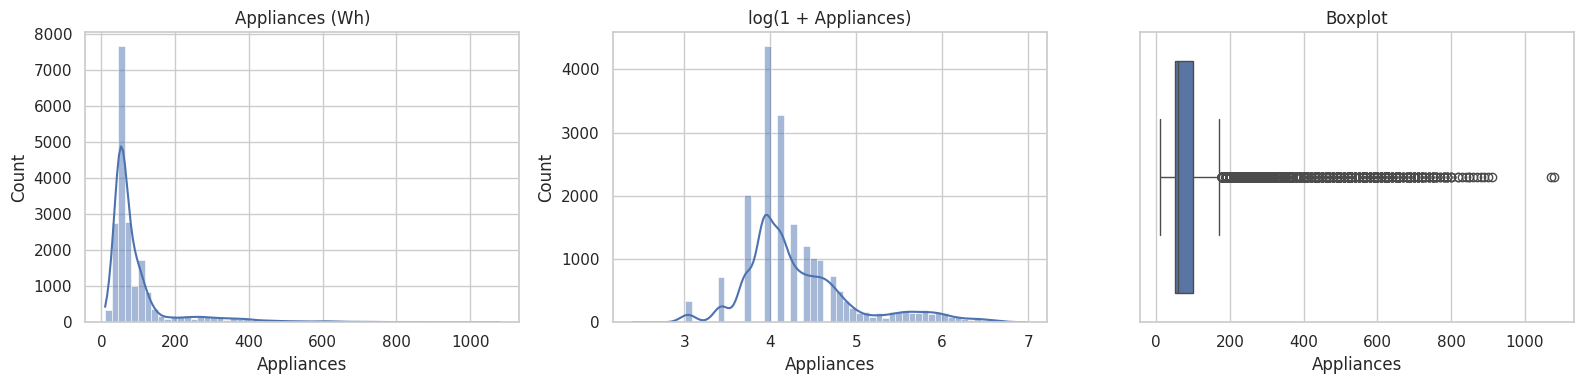

Skewness: 3.39
count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
50%         60.000000
90%        196.000000
95%        330.000000
99%        576.600000
max       1080.000000
Name: Appliances, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Appliances"], bins=60, kde=True, ax=ax[0]); ax[0].set_title("Appliances (Wh)")
sns.histplot(np.log1p(df["Appliances"]), bins=60, kde=True, ax=ax[1]); ax[1].set_title("log(1 + Appliances)")
sns.boxplot(x=df["Appliances"], ax=ax[2]); ax[2].set_title("Boxplot")
plt.tight_layout(); plt.show()

print("Skewness:", round(df["Appliances"].skew(), 2))
print(df["Appliances"].describe(percentiles=[.5, .9, .95, .99]))

The target is strongly right-skewed with a long tail of high-consumption spikes. These spikes matter later: they are the hardest to predict and the most likely to be flagged as 'unusual'.

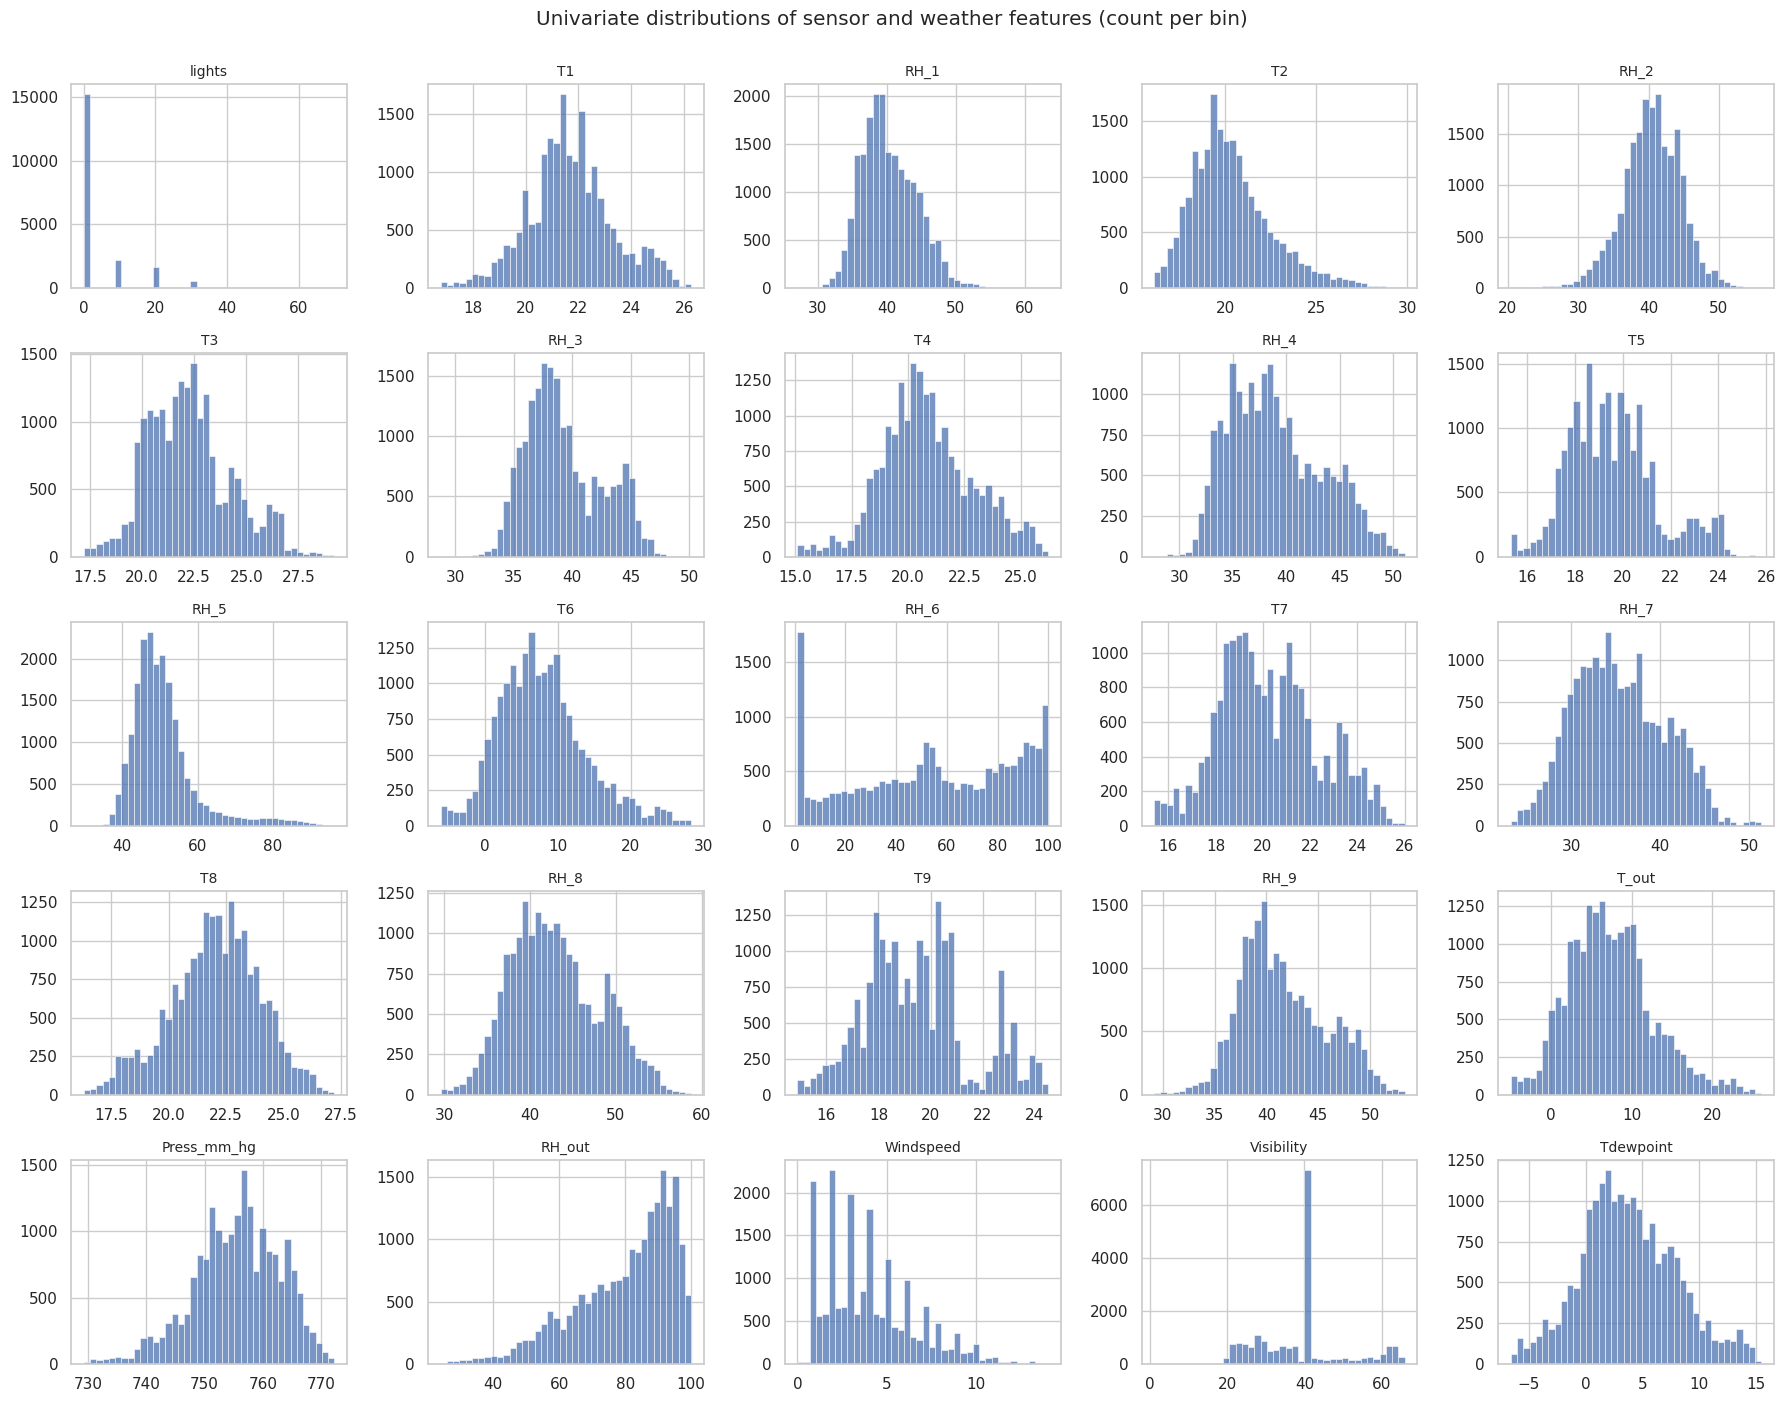

,skew,kurtosis
lights,2.20,4.46
RH_5,1.87,4.50
RH_out,-0.92,0.26
T2,0.89,0.93
Windspeed,0.86,0.25
T6,0.60,0.43
T5,0.56,0.11
T_out,0.53,0.36


In [8]:
feat_cols = [c for c in df.columns if c not in ["date", "Appliances", "rv1", "rv2"]]
fig, axes = plt.subplots(5, 5, figsize=(18, 14))
for ax, c in zip(axes.ravel(), feat_cols):
    sns.histplot(df[c], bins=40, ax=ax)
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(feat_cols):]:
    ax.set_visible(False)
plt.suptitle("Univariate distributions of sensor and weather features (count per bin)", y=1.0)
plt.tight_layout(); plt.show()

shape_stats = pd.DataFrame({"skew": df[feat_cols].skew(), "kurtosis": df[feat_cols].kurt()})
shape_stats.reindex(shape_stats["skew"].abs().sort_values(ascending=False).index).head(8).round(2)

### 2.2 Time patterns

### 2.0 Data-quality audit

data is clean

- The timestamps are in order, with no repeats and every step is exactly 10 minutes.
- There are no missing values, duplicate rows or constant columns.
- `rv1` and `rv2` are identical random-noise columns, so I drop both.
- Every humidity reading sits between 0 and 100 %, which is physically sensible.
- `lights` (22.7 %), `Visibility` (12.8 %) and `Appliances` (10.8 %) have the most outliers. They look like real events such as spikes in use, so I keep them instead of deleting them.

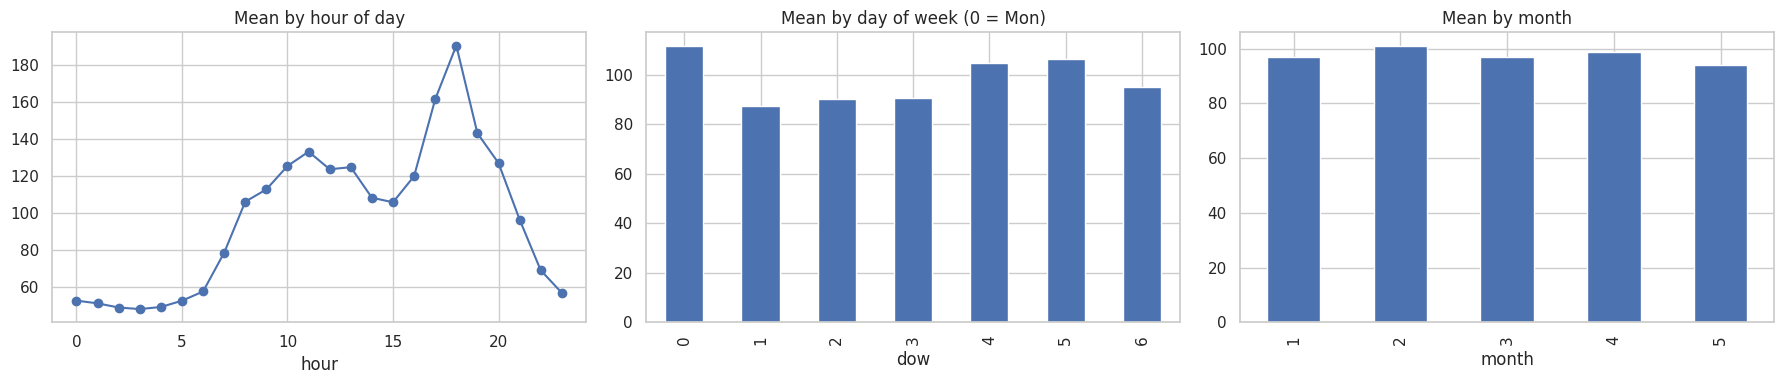

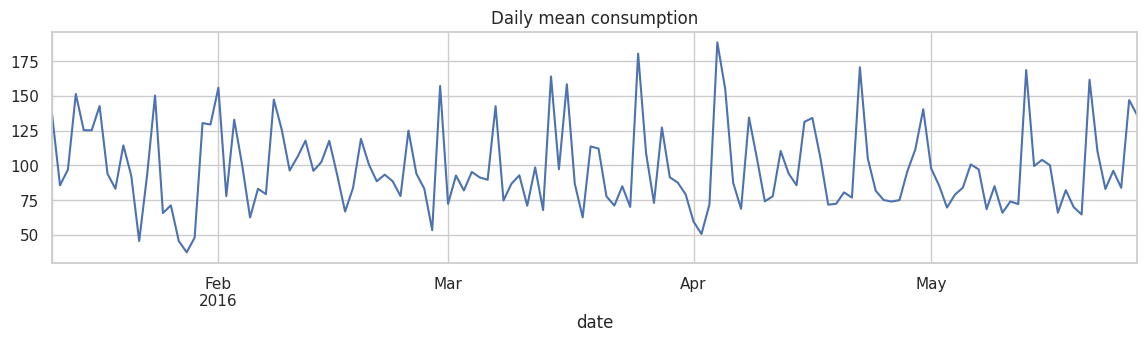

In [9]:
d = df.copy()
d["hour"] = d["date"].dt.hour
d["dow"] = d["date"].dt.dayofweek
d["month"] = d["date"].dt.month

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
d.groupby("hour")["Appliances"].mean().plot(ax=ax[0], marker="o"); ax[0].set_title("Mean by hour of day")
d.groupby("dow")["Appliances"].mean().plot(kind="bar", ax=ax[1]); ax[1].set_title("Mean by day of week (0 = Mon)")
d.groupby("month")["Appliances"].mean().plot(kind="bar", ax=ax[2]); ax[2].set_title("Mean by month")
plt.tight_layout(); plt.show()

d.set_index("date")["Appliances"].resample("D").mean().plot(figsize=(14, 3), title="Daily mean consumption")
plt.show()

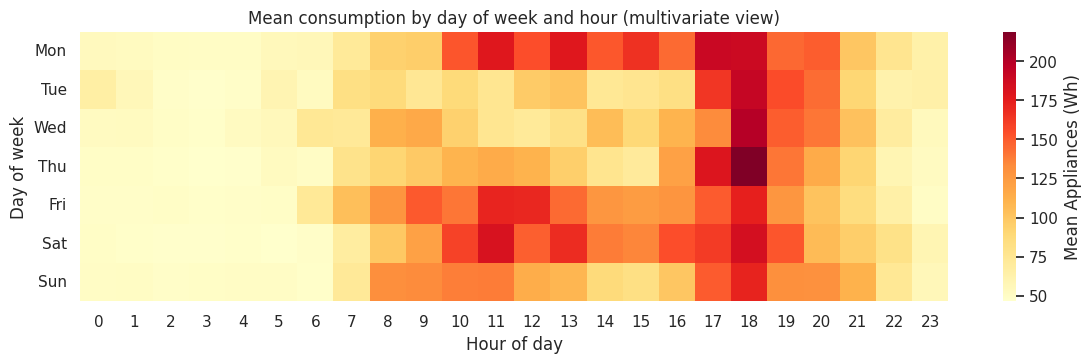

In [10]:
pivot = d.pivot_table(index="dow", columns="hour", values="Appliances", aggfunc="mean")
plt.figure(figsize=(14, 3.5))
sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": "Mean Appliances (Wh)"})
plt.yticks(np.arange(7) + .5, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
plt.xlabel("Hour of day"); plt.ylabel("Day of week")
plt.title("Mean consumption by day of week and hour (multivariate view)")
plt.show()

### 2.3 Relationships with the target

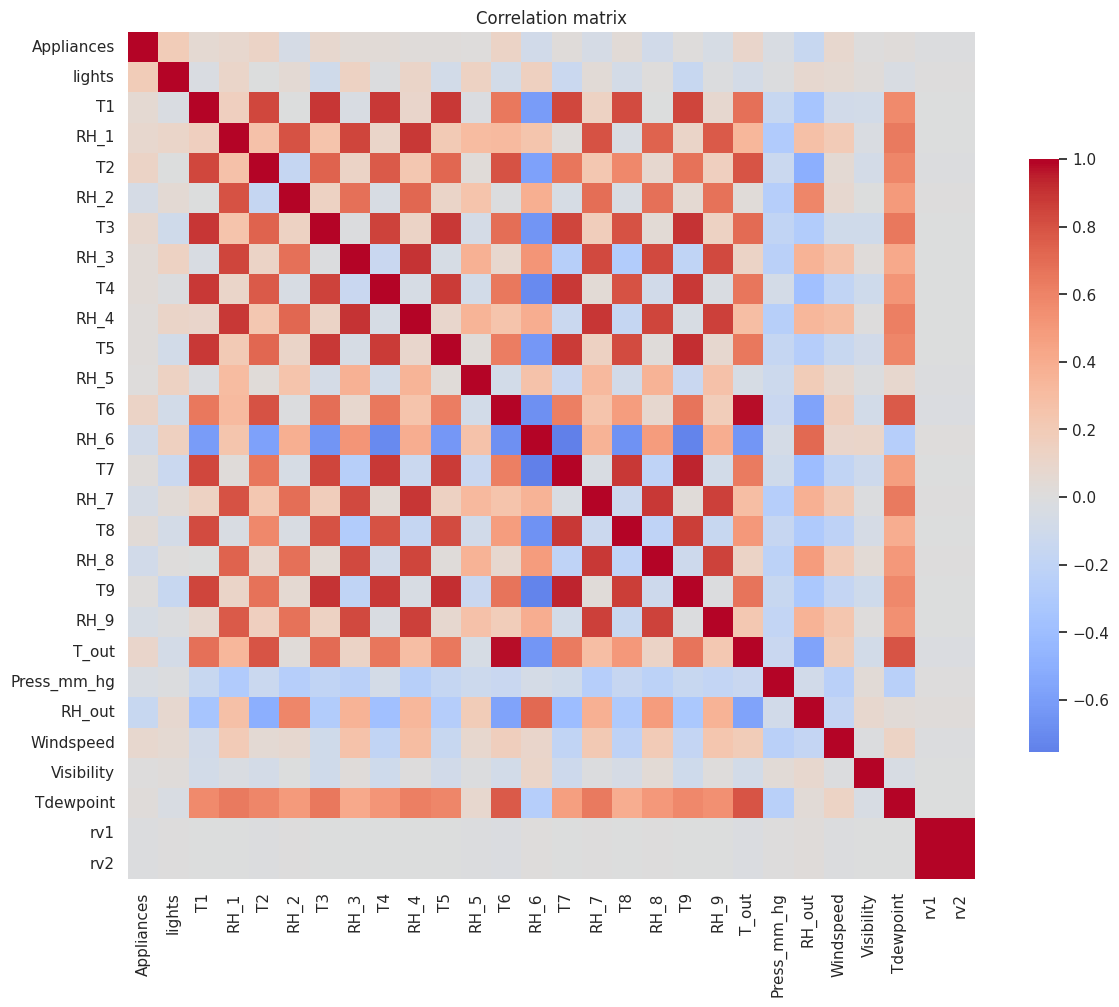

,Appliances
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638
T_out,0.099155
RH_8,-0.094039
Windspeed,0.087122
RH_1,0.086031
T3,0.085060
RH_6,-0.083178


In [11]:
num_cols = [c for c in df.columns if c != "date"]
corr = df[num_cols].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation matrix"); plt.show()

corr["Appliances"].drop("Appliances").sort_values(key=abs, ascending=False).head(10)

In [12]:
cmp_corr = pd.DataFrame({
    "pearson": df[num_cols].corr(method="pearson")["Appliances"],
    "spearman": df[num_cols].corr(method="spearman")["Appliances"],
}).drop(index="Appliances")
cmp_corr.reindex(cmp_corr["spearman"].abs().sort_values(ascending=False).index).head(10).round(3)

,pearson,spearman
T2,0.120,0.305
lights,0.197,0.302
RH_out,-0.152,-0.269
T1,0.055,0.244
T6,0.118,0.242
T8,0.040,0.236
RH_6,-0.083,-0.230
RH_8,-0.094,-0.217
T3,0.085,0.217
T_out,0.099,0.216


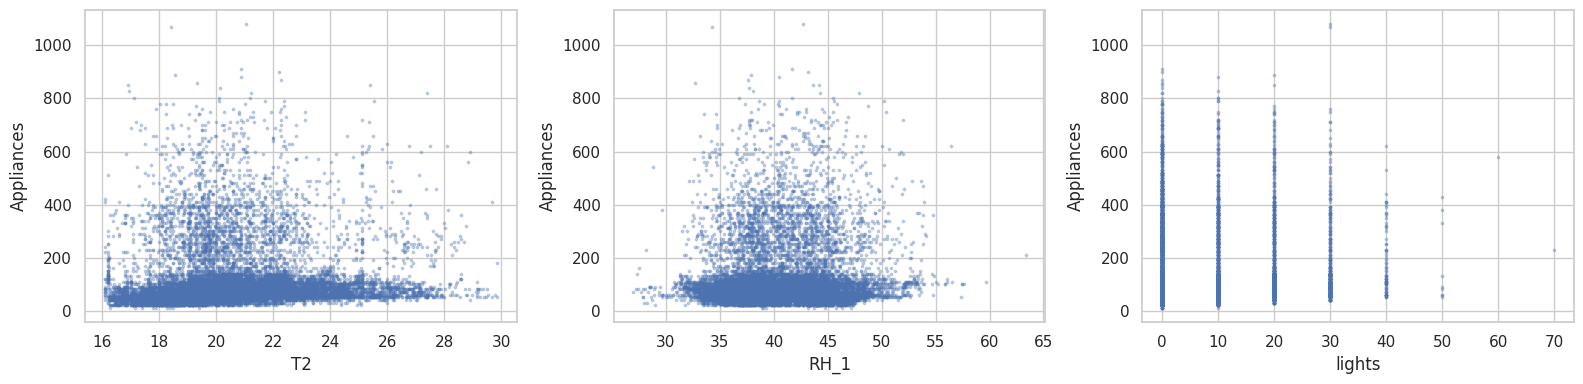

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ["T2", "RH_1", "lights"]):
    a.scatter(df[c], df["Appliances"], s=3, alpha=.3); a.set_xlabel(c); a.set_ylabel("Appliances")
plt.tight_layout(); plt.show()

## 3. PCA

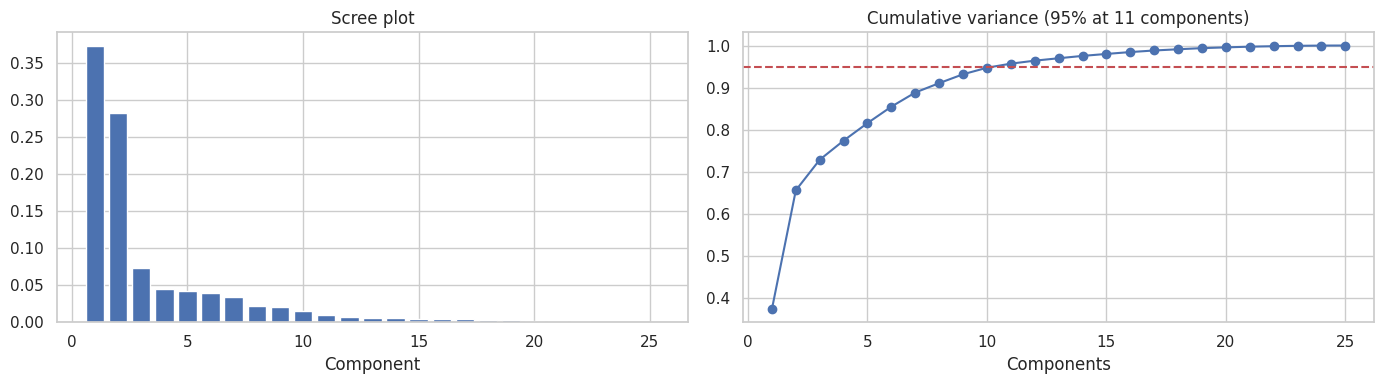

In [14]:
sensor_cols = [c for c in df.columns if c not in ["date", "Appliances", "rv1", "rv2"]]
X_pca = StandardScaler().fit_transform(df[sensor_cols])

pca = PCA().fit(X_pca)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n95 = int(np.argmax(cum >= 0.95)) + 1

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(1, len(evr) + 1), evr); ax[0].set_title("Scree plot"); ax[0].set_xlabel("Component")
ax[1].plot(range(1, len(cum) + 1), cum, marker="o"); ax[1].axhline(.95, color="r", ls="--")
ax[1].set_title(f"Cumulative variance (95% at {n95} components)"); ax[1].set_xlabel("Components")
plt.tight_layout(); plt.show()

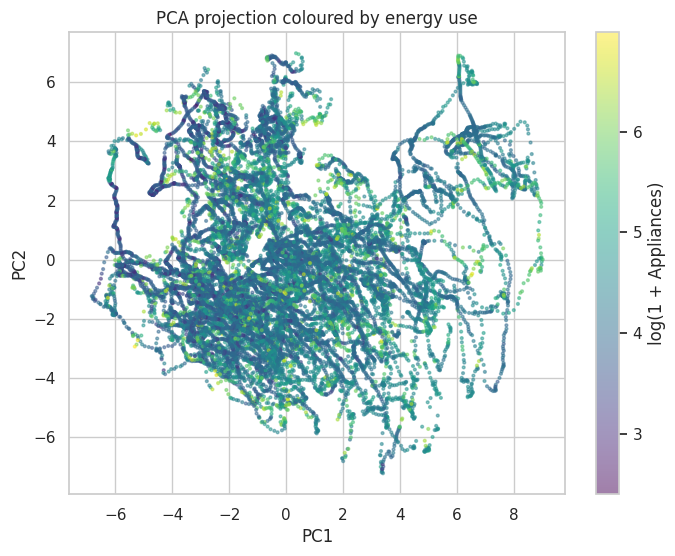

,PC1,PC2
T9,0.304527,-0.049230
T3,0.303848,0.012871
T1,0.300893,-0.009020
T5,0.299199,-0.001154
T4,0.297670,-0.050858
T7,0.295028,-0.084782
T_out,0.279487,0.055607
T2,0.279318,0.025102
T6,0.275792,0.040989
T8,0.268166,-0.094251


In [15]:
scores = PCA(n_components=2).fit_transform(X_pca)
plt.figure(figsize=(8, 6))
sc = plt.scatter(scores[:, 0], scores[:, 1], c=np.log1p(df["Appliances"]), cmap="viridis", s=4, alpha=.5)
plt.colorbar(sc, label="log(1 + Appliances)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA projection coloured by energy use")
plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=sensor_cols, columns=["PC1", "PC2"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(10)

In [16]:
pc_load = pd.DataFrame(pca.components_[:2].T, index=sensor_cols, columns=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    top = pc_load[pc].reindex(pc_load[pc].abs().sort_values(ascending=False).index).head(8)
    print(f"{pc} ({evr[int(pc[-1]) - 1]:.1%} of variance), strongest loadings:")
    print(top.round(3).to_string(), "\n")

PC1 (37.3% of variance), strongest loadings:
T9       0.305
T3       0.304
T1       0.301
T5       0.299
T4       0.298
T7       0.295
T_out    0.279
T2       0.279 

PC2 (28.3% of variance), strongest loadings:
RH_4         0.358
RH_3         0.349
RH_7         0.347
RH_8         0.346
RH_9         0.337
RH_1         0.332
RH_2         0.303
Tdewpoint    0.210 



## Principal Component Analysis (PCA) Results

### 1. Purpose of PCA

Principal Component Analysis (PCA) is a dimensionality-reduction technique used to transform correlated features into a smaller set of new variables called principal components. The goal is to retain as much information as possible while reducing the number of dimensions.

In this project, PCA was applied to standardized sensor and weather features to explore the underlying patterns in the dataset.

### 2. Explained Variance Results

The first two principal components explain the following proportions of the total feature variance:

| Principal Component | Explained Variance |
|---|---:|
| PC1 | 37.3% |
| PC2 | 28.3% |
| **Combined** | **65.6%** |

PC1 explains 37.3% of the variance, while PC2 explains 28.3%. Together, they capture 65.6% of the total variance in the standardized features.

### 3. Principal Component Loadings

The component loadings indicate which original features contribute most strongly to each principal component.

**PC1 — Temperature-related variation**

The strongest loadings for PC1 are:

| Feature | Loading |
|---|---:|
| T9 | 0.305 |
| T3 | 0.304 |
| T1 | 0.301 |
| T5 | 0.299 |
| T4 | 0.298 |
| T7 | 0.295 |
| T_out | 0.279 |
| T2 | 0.279 |

These results suggest that PC1 primarily captures a shared temperature-related pattern across indoor and outdoor measurements.

**PC2 — Humidity-related variation**

The strongest loadings for PC2 are:

| Feature | Loading |
|---|---:|
| RH_4 | 0.358 |
| RH_3 | 0.349 |
| RH_7 | 0.347 |
| RH_8 | 0.346 |
| RH_9 | 0.337 |
| RH_1 | 0.332 |
| RH_2 | 0.303 |
| Tdewpoint | 0.210 |

These loadings suggest that PC2 primarily represents a shared humidity-related pattern.

### 4. PCA Model Performance

PCA was evaluated using Ridge regression with time-series cross-validation. The notebook reports the following cross-validation RMSE values:

| Model | CV RMSE |
|---|---:|
| Ridge with raw features | 97.244 |
| Ridge with PCA (11 components) | 97.471 |
| Ridge with PCA (2 components) | 97.290 |

Lower RMSE indicates better predictive performance.

The Ridge model using the original features achieved the lowest RMSE of **97.244**. Both PCA-based models performed slightly worse:

- PCA with 11 components increased RMSE to 97.471.
- PCA with 2 components increased RMSE to 97.290.

### 5. Conclusion

PCA successfully identified underlying patterns in the sensor and weather features. The first principal component was mainly associated with temperature measurements, while the second was mainly associated with humidity measurements.

However, PCA did not improve the cross-validation performance of Ridge regression. Therefore, the notebook retains PCA as an exploratory data analysis and interpretation technique rather than using it as a predictive-model improvement.

**Overall, the PCA results show that dimensionality reduction can reveal relationships among features, but reducing the number of dimensions does not necessarily improve prediction accuracy.**

## 4. Preprocessing and feature engineering

In [17]:
def engineer(frame):
    f = frame.sort_values("date").reset_index(drop=True).copy()
    f["hour"] = f["date"].dt.hour + f["date"].dt.minute / 60
    f["dow"] = f["date"].dt.dayofweek
    f["weekend"] = (f["dow"] >= 5).astype(int)
    f["month"] = f["date"].dt.month
    f["hour_sin"] = np.sin(2 * np.pi * f["hour"] / 24)
    f["hour_cos"] = np.cos(2 * np.pi * f["hour"] / 24)
    t_in = [f"T{i}" for i in range(1, 10) if i != 6]
    rh_in = [f"RH_{i}" for i in range(1, 10) if i != 6]
    f["T_in_mean"] = f[t_in].mean(axis=1)
    f["RH_in_mean"] = f[rh_in].mean(axis=1)
    f["T_diff"] = f["T_in_mean"] - f["T_out"]
    return f

data = engineer(df)
dates = data["date"]
y = data["Appliances"]
X = data.drop(columns=["date", "Appliances", "rv1", "rv2"])

split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
dates_test = dates.iloc[split:]

print("Features:", X.shape[1])
print("Train:", dates.iloc[0].date(), "->", dates.iloc[split - 1].date())
print("Test :", dates.iloc[split].date(), "->", dates.iloc[-1].date())

Features: 34
Train: 2016-01-11 -> 2016-04-30
Test : 2016-04-30 -> 2016-05-27


### 4.1 Feature-set selection with a drift screen


In [18]:
X_all = data.drop(columns=["date", "Appliances", "rv1", "rv2"])
X_train_all = X_all.iloc[:split]

time_cols = ["hour", "hour_sin", "hour_cos", "dow", "weekend"]

# Drift screen, TRAIN period only (no test information is used)
from scipy.stats import ks_2samp
KS_THRESHOLD = 0.30          # fixed once, before looking at any test result
half = split // 2
ks = pd.Series({c: ks_2samp(X_train_all[c].iloc[:half], X_train_all[c].iloc[half:]).statistic
                for c in X_all.columns if c not in time_cols}).sort_values(ascending=False)
dropped = ks[ks > KS_THRESHOLD].index.tolist()
stable_cols = [c for c in X_all.columns if c not in dropped]
print(f"Drift screen: kept {len(stable_cols)} of {X_all.shape[1]} features")
print("Dropped:", dropped)
display(ks.head(12).round(2).to_frame("KS statistic (train: first half vs second half)"))

candidates = {
    "All features": list(X_all.columns),
    "Without month": [c for c in X_all.columns if c != "month"],
    "Drift-screened (selected)": stable_cols,
    "Time + lights": time_cols + ["lights"],
    "Time only": time_cols,
}

# For information: time-ordered CV on the TRAIN period only
tscv = TimeSeriesSplit(n_splits=4)
rows = []
for name, cols in candidates.items():
    fold_rmse = []
    for tr, va in tscv.split(X_train_all):
        m = LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=80,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          random_state=RANDOM_STATE, verbose=-1)
        m.fit(X_train_all.iloc[tr][cols], y_train.iloc[tr])
        p = m.predict(X_train_all.iloc[va][cols])
        fold_rmse.append(np.sqrt(mean_squared_error(y_train.iloc[va], p)))
    rows.append({"feature_set": name, "n_features": len(cols), "cv_rmse": float(np.mean(fold_rmse))})

base_rmse = [np.sqrt(mean_squared_error(y_train.iloc[va], np.full(len(va), y_train.iloc[tr].mean())))
             for tr, va in tscv.split(X_train_all)]
rows.append({"feature_set": "(mean baseline)", "n_features": 0, "cv_rmse": float(np.mean(base_rmse))})
display(pd.DataFrame(rows).set_index("feature_set").round(3))

# Selected by the stability rule above, not by CV or test score
FEATURES = stable_cols
print("Selected feature set: drift-screened ->", len(FEATURES), "features")

X = X_all[FEATURES]
X_train, X_test = X.iloc[:split], X.iloc[split:]

Drift screen: kept 16 of 34 features
Dropped: ['month', 'T9', 'RH_6', 'T7', 'T_in_mean', 'T8', 'T3', 'RH_3', 'T5', 'T4', 'RH_8', 'RH_in_mean', 'RH_4', 'RH_5', 'RH_7', 'RH_9', 'T1', 'RH_1']


,KS statistic (train: first half vs second half)
month,0.90
T9,0.81
RH_6,0.77
T7,0.66
T_in_mean,0.58
T8,0.56
T3,0.54
RH_3,0.54
T5,0.53
T4,0.50


,n_features,cv_rmse
feature_set,,
All features,34,94.196
Without month,33,94.300
Drift-screened (selected),16,96.222
Time + lights,6,96.661
Time only,5,96.005
(mean baseline),0,99.893


Selected feature set: drift-screened -> 16 features


In [19]:
X_test_all = X_all.iloc[split:]
drift_rows = []
for name, cols in candidates.items():
    m = LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=80,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      random_state=RANDOM_STATE, verbose=-1)
    m.fit(X_train_all[cols], y_train)
    p = m.predict(X_test_all[cols])
    drift_rows.append({"feature_set": name, "n_features": len(cols),
                       "test_RMSE": np.sqrt(mean_squared_error(y_test, p)),
                       "test_MAE": mean_absolute_error(y_test, p),
                       "test_R2": r2_score(y_test, p),
                       "mean_residual": float(np.mean(y_test.values - p))})

p0 = np.full(len(y_test), y_train.mean())
drift_rows.append({"feature_set": "(mean baseline)", "n_features": 0,
                   "test_RMSE": np.sqrt(mean_squared_error(y_test, p0)),
                   "test_MAE": mean_absolute_error(y_test, p0),
                   "test_R2": r2_score(y_test, p0),
                   "mean_residual": float(np.mean(y_test.values - p0))})
pd.DataFrame(drift_rows).set_index("feature_set").round(3)

,n_features,test_RMSE,test_MAE,test_R2,mean_residual
feature_set,,,,,
All features,34,116.435,88.856,-0.636,-64.604
Without month,33,107.229,79.158,-0.387,-53.173
Drift-screened (selected),16,88.612,47.682,0.053,1.118
Time + lights,6,85.167,43.338,0.125,3.320
Time only,5,85.452,46.304,0.119,-2.368
(mean baseline),0,91.053,52.685,-0.000,-1.647


### 4.2 Preprocessing pipeline and leakage checks



In [20]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV

pass_cols = [c for c in ["weekend", "hour_sin", "hour_cos"] if c in X_train.columns]
scale_cols = [c for c in X_train.columns if c not in pass_cols]

def make_preprocessor():
    return ColumnTransformer([
        ("scale", Pipeline([("impute", SimpleImputer(strategy="median")),
                            ("scaler", StandardScaler())]), scale_cols),
        ("keep", "passthrough", pass_cols),
    ])

def rmse(y_true, p):
    return float(np.sqrt(mean_squared_error(y_true, p)))

def cv_rmse(estimator, Xtr, ytr, n_splits=4):
    """Mean RMSE over time-ordered folds; the estimator is cloned so nothing already fitted is touched."""
    scores = []
    for tr, va in TimeSeriesSplit(n_splits=n_splits).split(Xtr):
        m = clone(estimator).fit(Xtr.iloc[tr], ytr.iloc[tr])
        scores.append(rmse(ytr.iloc[va], m.predict(Xtr.iloc[va])))
    return float(np.mean(scores))

def upsert(entry):
    """Add or replace a row in `results` so re-running a cell never creates duplicates."""
    results[:] = [r for r in results if r["model"] != entry["model"]] + [entry]

# Leakage check: the scaler statistics must equal the TRAIN means, not train+test means
prep_check = make_preprocessor().fit(X_train)
assert np.allclose(prep_check.named_transformers_["scale"].named_steps["scaler"].mean_,
                   X_train[scale_cols].mean().values)
print("Scaler fitted on training rows only:", True)
print("Training period ends before test period starts:", X_train.index.max() < X_test.index.min())
print("Train-fitted preprocessing applied to test:", prep_check.transform(X_test).shape)

Scaler fitted on training rows only: True
Training period ends before test period starts: True
Train-fitted preprocessing applied to test: (3947, 16)


In [21]:
n_comp = min(n95, X_train.shape[1])
pca_candidates = {
    "Ridge, raw features": Pipeline([("prep", make_preprocessor()), ("ridge", Ridge(alpha=10))]),
    f"Ridge + PCA ({n_comp} components)": Pipeline([("prep", make_preprocessor()),
                                                     ("pca", PCA(n_components=n_comp)),
                                                     ("ridge", Ridge(alpha=10))]),
    "Ridge + PCA (2 components)": Pipeline([("prep", make_preprocessor()),
                                             ("pca", PCA(n_components=min(2, X_train.shape[1]))),
                                             ("ridge", Ridge(alpha=10))]),
}
pca_cv = pd.DataFrame({"cv_rmse": {k: cv_rmse(v, X_train, y_train) for k, v in pca_candidates.items()}}).round(3)
display(pca_cv)

raw_cv = pca_cv.iloc[0, 0]
if pca_cv.iloc[1:, 0].min() < raw_cv:
    print("Decision: PCA lowers CV RMSE, so it is worth keeping in the pipeline.")
else:
    print("Decision: PCA does not lower CV RMSE, so it is kept as an EDA and understanding tool only.")

,cv_rmse
"Ridge, raw features",97.244
Ridge + PCA (11 components),97.471
Ridge + PCA (2 components),97.290


Decision: PCA does not lower CV RMSE, so it is kept as an EDA and understanding tool only.


# 4. Preprocessing and Feature Engineering Results

## 4.1 Data Preprocessing

The dataset was checked for missing values, duplicate records, and data types before feature engineering.

| Data quality check | Result |
|---|---:|
| Total observations | 19,735 |
| Original columns | 29 |
| Missing values | 0 |
| Duplicate rows | 0 |
| Dataset start | 11 January 2016 |
| Dataset end | 27 May 2016 |
| Target variable | `Appliances` |
| Target mean consumption | 97.69 Wh |

The dataset contained no missing values or duplicate rows. The date column was converted to a datetime format to support time-based feature extraction and chronological splitting.

An 80:20 chronological split was used. The training data covered 11 January to 30 April 2016, while the test data covered 30 April to 27 May 2016. The split preserved the order of observations, allowing the models to be evaluated on a later period.

## 4.2 Feature Engineering

The `engineer()` function created new features from the timestamp and existing sensor measurements.

| Engineered feature | Description |
|---|---|
| `hour` | Hour of the day, including fractional hours |
| `dow` | Day of the week, from 0 (Monday) to 6 (Sunday) |
| `weekend` | 1 for Saturday or Sunday, otherwise 0 |
| `month` | Calendar month |
| `hour_sin` | Sine transformation of the hour |
| `hour_cos` | Cosine transformation of the hour |
| `T_in_mean` | Mean of the selected indoor temperature sensors |
| `RH_in_mean` | Mean of the selected indoor relative-humidity sensors |
| `T_diff` | Mean indoor temperature minus outdoor temperature |

The sine and cosine transformations represent time cyclically. This helps the model understand that times near midnight are close together rather than treating 23:00 and 00:00 as far apart.

The indoor temperature and humidity averages summarize information from multiple sensors, while `T_diff` represents the difference between indoor and outdoor temperature.

After feature engineering and removing the date, target, and two random variables (`rv1` and `rv2`) from the predictors, the notebook produced **34 candidate features**.

## 4.3 Feature Selection Using Drift Screening

The notebook used the Kolmogorov–Smirnov (KS) statistic to compare the first and second halves of the training period. Features with a KS statistic greater than 0.30 were excluded from the selected feature set to reduce the influence of features whose distributions changed substantially over time.

| Feature-set strategy | Number of features | Cross-validation RMSE |
|---|---:|---:|
| All features | 34 | 94.196 |
| Without month | 33 | 94.300 |
| Drift-screened (selected) | 16 | 96.222 |
| Time + lights | 6 | 96.661 |
| Time only | 5 | 96.005 |
| Mean baseline | 0 | 99.893 |

The drift screen retained **16 of the 34 candidate features** and excluded 18 features:

`month`, `T9`, `RH_6`, `T7`, `T_in_mean`, `T8`, `T3`, `RH_3`, `T5`, `T4`, `RH_8`, `RH_in_mean`, `RH_4`, `RH_5`, `RH_7`, `RH_9`, `T1`, and `RH_1`.

The largest observed KS statistics included `month` (0.90), `T9` (0.81), and `RH_6` (0.77), indicating substantial distribution differences between the two training-period halves.

The all-feature model achieved the lowest cross-validation RMSE (94.196) among these candidates. Therefore, the drift-screened set was **not the best candidate by cross-validation RMSE**. It was selected because of the predefined stability-screening rule, rather than because it produced the lowest score.

## 4.4 Test-Set Comparison of Feature Sets

The saved test-set results were:

| Feature set | Features | Test RMSE (Wh) | Test MAE (Wh) | Test R² |
|---|---:|---:|---:|---:|
| All features | 34 | 116.435 | 88.856 | -0.636 |
| Without month | 33 | 107.229 | 79.158 | -0.387 |
| Drift-screened (selected) | 16 | 88.612 | 47.682 | 0.053 |
| **Time + lights** | **6** | **85.167** | **43.338** | **0.125** |
| Time only | 5 | 85.452 | 46.304 | 0.119 |
| Mean baseline | 0 | 91.053 | 52.685 | -0.000 |

Among these feature-set candidates, **Time + lights performed best on the test set**, with RMSE of 85.167 Wh, MAE of 43.338 Wh, and R² of 0.125.

The result suggests that time-related patterns and lighting consumption were useful predictors in this particular test period. Adding all available features did not guarantee better performance, potentially because some features changed distribution over time.

However, the feature-set comparison uses the same test period to report performance across multiple candidates. These results are useful for describing the experiment, but the test-set winner should not be treated as an unbiased final model-selection result.

## 4.5 Preprocessing Pipeline and Leakage Checks

The notebook used a preprocessing pipeline consisting of median imputation and standardization for selected numeric features. The `weekend`, `hour_sin`, and `hour_cos` columns were passed through without standardization.

| Validation check | Saved result |
|---|---|
| Scaler fitted using training rows only | Passed |
| Training data precedes test data | Passed |
| Test matrix shape after preprocessing | `(3947, 16)` |

The scaler's fitted means were checked against the training-set means, and the notebook confirmed that the preprocessing transformation produced a test matrix with 3,947 rows and 16 features.

These checks support the claim that the scaler was fitted on training data only. They do not, by themselves, establish that every possible source of leakage has been eliminated.

## 4.6 Overall Conclusion

The preprocessing and feature-engineering stage converted the original dataset into 34 candidate predictors by adding time-based, cyclic, and aggregate sensor features. A predefined KS-based drift screen then reduced the selected set to 16 features.

The results show that feature selection materially affected model performance. The selected drift-screened feature set improved considerably over the mean baseline, but the six-feature `Time + lights` set performed best in the saved test comparison. The preprocessing pipeline also passed its explicit checks for training-only scaler fitting and chronological splitting.

Overall, feature engineering created useful representations of time and environmental conditions, while drift screening reduced the number of predictors. The comparison also demonstrates that a smaller feature set can perform better than a larger one, although the strongest test-set result should be confirmed using model selection based on training-only cross-validation.

## 5. Models

In [22]:
def evaluate(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    p = model.predict(Xte)
    return {"model": name,
            "RMSE": np.sqrt(mean_squared_error(yte, p)),
            "MAE": mean_absolute_error(yte, p),
            "R2": r2_score(yte, p)}, model, p

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Ridge": Pipeline([("scale", StandardScaler()), ("ridge", Ridge(alpha=10))]),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1),
}

results, fitted, preds = [], {}, {}
for name, m in models.items():
    r, fm, p = evaluate(name, m, X_train, y_train, X_test, y_test)
    results.append(r); fitted[name] = fm; preds[name] = p

pd.DataFrame(results).set_index("model").round(3)

,RMSE,MAE,R2
model,,,
Mean baseline,91.053,52.685,-0.000
Ridge,87.366,49.388,0.079
Random Forest,109.943,72.211,-0.458
LightGBM,95.567,56.696,-0.102


**Hour-of-day baseline.** A fairer yardstick than the global mean: predict the average training consumption for the same hour of day. A model that cannot beat this has learned nothing beyond the daily rhythm.

In [23]:
hr_all = np.floor(data["hour"]).astype(int)
hour_profile = y_train.groupby(hr_all.iloc[:split]).mean()
p_hour = hr_all.iloc[split:].map(hour_profile).values

upsert({"model": "Hour-of-day baseline",
        "RMSE": rmse(y_test, p_hour),
        "MAE": mean_absolute_error(y_test, p_hour),
        "R2": r2_score(y_test, p_hour)})
preds["Hour-of-day baseline"] = p_hour
pd.DataFrame(results).set_index("model").round(3)

,RMSE,MAE,R2
model,,,
Mean baseline,91.053,52.685,-0.000
Ridge,87.366,49.388,0.079
Random Forest,109.943,72.211,-0.458
LightGBM,95.567,56.696,-0.102
Hour-of-day baseline,85.482,46.947,0.118


Four regression models were evaluated: Mean Baseline, Ridge Regression, Random Forest, and LightGBM. An hour-of-day baseline was also included for comparison.

The initial Ridge model achieved an RMSE of 87.366 Wh, while the hour-of-day baseline achieved 85.482 Wh. The default Random Forest and LightGBM performed worse, showing that model complexity alone does not guarantee better predictions.

## 6. AutoML (FLAML)

In [24]:
from flaml import AutoML

automl = AutoML()
automl.fit(
    X_train, y_train,
    task="regression",
    metric="rmse",
    time_budget=120,                 # seconds; increase for a more thorough search
    eval_method="cv", n_splits=3, split_type="time",
    estimator_list=["lgbm", "rf", "extra_tree", "xgboost"],
    seed=RANDOM_STATE, verbose=0,
)

print("Best estimator:", automl.best_estimator)
print("Best config   :", automl.best_config)

lb = pd.DataFrame({"cv_rmse": automl.best_loss_per_estimator}).T
lb.index.name = "estimator"
print("\nCV RMSE per estimator:")
print(lb.T.sort_values("cv_rmse").round(3))

Best estimator: extra_tree
Best config   : {'n_estimators': 6, 'max_features': np.float64(0.7744609824175921), 'max_leaves': 9}

CV RMSE per estimator:
estimator   cv_rmse
extra_tree   93.861
lgbm         94.667
xgboost      94.835
rf           95.297


In [25]:
p_auto = automl.predict(X_test)
auto_res = {"model": f"AutoML ({automl.best_estimator})",
            "RMSE": np.sqrt(mean_squared_error(y_test, p_auto)),
            "MAE": mean_absolute_error(y_test, p_auto),
            "R2": r2_score(y_test, p_auto)}
preds[auto_res["model"]] = p_auto
results.append(auto_res)
pd.DataFrame([auto_res]).set_index("model").round(3)

,RMSE,MAE,R2
model,,,
AutoML (extra_tree),85.447,43.867,0.119


FLAML automatically compared several algorithms using time-series cross-validation. Extra Trees was selected as the best estimator, with a cross-validation RMSE of 93.861.

On the test set, AutoML achieved an RMSE of 85.447 Wh, MAE of 43.867 Wh, and R² of 0.119. It achieved the lowest MAE among the evaluated Track A models, demonstrating the usefulness of automated model selection.

## 7. Hyperparameter tuning (LightGBM)

In [26]:
param_dist = {
    "n_estimators": [200, 400, 600, 800],
    "learning_rate": [0.01, 0.02, 0.05, 0.1],
    "num_leaves": [15, 31, 63, 127],
    "min_child_samples": [10, 20, 40, 80],
    "subsample": [0.6, 0.8, 1.0],
    "subsample_freq": [1],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [0, 1, 5, 10],
}

search = RandomizedSearchCV(
    LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),
    param_distributions=param_dist,
    n_iter=25,
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=-1, verbose=0,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV RMSE:", round(-search.best_score_, 3))

Best params: {'subsample_freq': 1, 'subsample': 0.8, 'reg_lambda': 10, 'num_leaves': 63, 'n_estimators': 400, 'min_child_samples': 40, 'learning_rate': 0.01, 'colsample_bytree': 0.6}
Best CV RMSE: 95.156


In [27]:
best_lgbm = search.best_estimator_
p_tuned = best_lgbm.predict(X_test)
tuned_res = {"model": "LightGBM (tuned)",
             "RMSE": np.sqrt(mean_squared_error(y_test, p_tuned)),
             "MAE": mean_absolute_error(y_test, p_tuned),
             "R2": r2_score(y_test, p_tuned)}
preds["LightGBM (tuned)"] = p_tuned
results.append(tuned_res)
pd.DataFrame([tuned_res]).set_index("model").round(3)

,RMSE,MAE,R2
model,,,
LightGBM (tuned),86.807,47.315,0.091


In [28]:
lb2 = pd.DataFrame({"cv_rmse": pd.Series(automl.best_loss_per_estimator)}).sort_values("cv_rmse")
cfgs = getattr(automl, "best_config_per_estimator", {}) or {}
lb2["n_estimators"] = [(cfgs.get(k) or {}).get("n_estimators", np.nan) for k in lb2.index]
display(lb2.round(3))

base3 = float(np.mean([rmse(y_train.iloc[va], np.full(len(va), y_train.iloc[tr].mean()))
                       for tr, va in TimeSeriesSplit(n_splits=3).split(X_train)]))
print(f"Mean baseline, 3-fold time-ordered CV : {base3:.2f}")
print(f"AutoML best ({automl.best_estimator}), 3-fold CV      : {lb2['cv_rmse'].iloc[0]:.2f}")
print(f"Manual tuned LightGBM, 4-fold CV      : {-search.best_score_:.2f}")
print(f"AutoML test RMSE                      : {auto_res['RMSE']:.2f}")

,cv_rmse,n_estimators
extra_tree,93.861,6
lgbm,94.667,5
xgboost,94.835,71
rf,95.297,33


Mean baseline, 3-fold time-ordered CV : 100.70
AutoML best (extra_tree), 3-fold CV      : 93.86
Manual tuned LightGBM, 4-fold CV      : 95.16
AutoML test RMSE                      : 85.45


### 7.2 Tuning Ridge and Random Forest, search-space rationale, and gains from tuning



In [29]:
# Ridge: tune alpha inside the preprocessing pipeline (scaler refitted in every fold)
ridge_pipe = Pipeline([("prep", make_preprocessor()), ("ridge", Ridge())])
ridge_search = GridSearchCV(
    ridge_pipe, {"ridge__alpha": [0.1, 1, 10, 100, 1000, 10000]},
    cv=TimeSeriesSplit(n_splits=4), scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_search.fit(X_train, y_train)
print("Ridge best:", ridge_search.best_params_, "| CV RMSE:", round(-ridge_search.best_score_, 3))

# Random Forest: constrained search space
rf_dist = {
    "n_estimators": [200],
    "max_depth": [3, 5, 8, 12],
    "min_samples_leaf": [20, 50, 100, 200],
    "max_features": [0.3, 0.5, 1.0],
}
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    rf_dist, n_iter=10, cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train, y_train)
print("Random Forest best:", rf_search.best_params_, "| CV RMSE:", round(-rf_search.best_score_, 3))

# One test evaluation for each tuned model
for label, est in [("Ridge (tuned)", ridge_search.best_estimator_),
                   ("Random Forest (tuned)", rf_search.best_estimator_)]:
    p = est.predict(X_test)
    preds[label] = p
    upsert({"model": label, "RMSE": rmse(y_test, p),
            "MAE": mean_absolute_error(y_test, p), "R2": r2_score(y_test, p)})

# Gains from tuning, quantified on CV (training period) and on the test period
res_lookup = pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model")
gain_rows = []
for base_name, tuned_name, tuned_cv in [
        ("Ridge", "Ridge (tuned)", -ridge_search.best_score_),
        ("Random Forest", "Random Forest (tuned)", -rf_search.best_score_),
        ("LightGBM", "LightGBM (tuned)", -search.best_score_)]:
    gain_rows.append({"model": base_name,
                      "CV_RMSE_default": cv_rmse(models[base_name], X_train, y_train),
                      "CV_RMSE_tuned": tuned_cv,
                      "test_RMSE_default": res_lookup.loc[base_name, "RMSE"],
                      "test_RMSE_tuned": res_lookup.loc[tuned_name, "RMSE"]})
gains = pd.DataFrame(gain_rows).set_index("model")
gains["test_RMSE_gain"] = gains["test_RMSE_default"] - gains["test_RMSE_tuned"]
gains.round(3)

Ridge best: {'ridge__alpha': 10000} | CV RMSE: 95.794
Random Forest best: {'n_estimators': 200, 'min_samples_leaf': 100, 'max_features': 0.3, 'max_depth': 8} | CV RMSE: 93.059


,CV_RMSE_default,CV_RMSE_tuned,test_RMSE_default,test_RMSE_tuned,test_RMSE_gain
model,,,,,
Ridge,97.248,95.794,87.366,87.777,-0.412
Random Forest,107.012,93.059,109.943,84.513,25.430
LightGBM,104.975,95.156,95.567,86.807,8.760


Randomized search and grid search were used to improve LightGBM, Random Forest, and Ridge Regression.

Tuning reduced Random Forest's test RMSE from 109.943 to 84.513 Wh and LightGBM's from 95.567 to 86.807 Wh. However, tuned Ridge achieved an RMSE of 87.777 Wh, slightly worse than its default version.

These results show that hyperparameter tuning can improve generalisation, but improvements depend on the model and parameter settings.

## 8. Evaluation

,RMSE,MAE,R2
model,,,
Random Forest (tuned),84.513,44.184,0.138
AutoML (extra_tree),85.447,43.867,0.119
Hour-of-day baseline,85.482,46.947,0.118
LightGBM (tuned),86.807,47.315,0.091
Ridge,87.366,49.388,0.079
Ridge (tuned),87.777,52.865,0.070
Mean baseline,91.053,52.685,-0.000
LightGBM,95.567,56.696,-0.102
Random Forest,109.943,72.211,-0.458


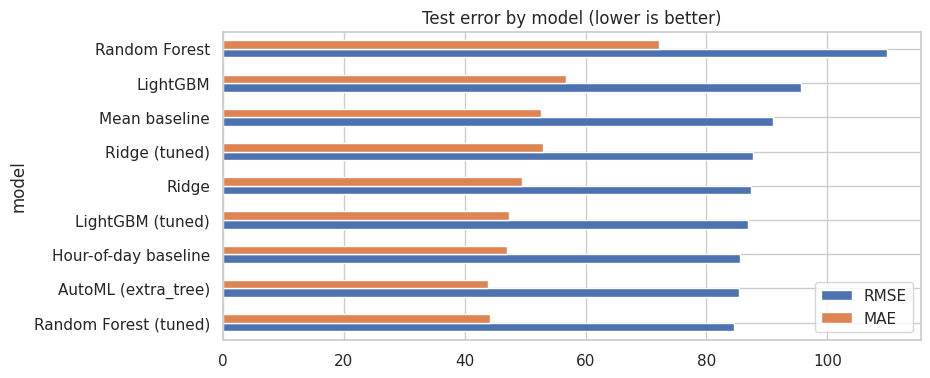

In [30]:
res_df = pd.DataFrame(results).set_index("model").round(3).sort_values("RMSE")
display(res_df)

res_df[["RMSE", "MAE"]].plot(kind="barh", figsize=(9, 4), title="Test error by model (lower is better)")
plt.show()

In [31]:
# Success criterion 1 (section 0): beat BOTH baselines on RMSE and MAE, with R2 > 0
mb, hb = res_df.loc["Mean baseline"], res_df.loc["Hour-of-day baseline"]
check = res_df.drop(index=["Mean baseline", "Hour-of-day baseline"]).copy()
check["beats_mean"] = (check["RMSE"] < mb["RMSE"]) & (check["MAE"] < mb["MAE"])
check["beats_hour"] = (check["RMSE"] < hb["RMSE"]) & (check["MAE"] < hb["MAE"])
check["R2_above_0"] = check["R2"] > 0
check["meets_criterion_1"] = check[["beats_mean", "beats_hour", "R2_above_0"]].all(axis=1)
check[["RMSE", "MAE", "R2", "beats_mean", "beats_hour", "R2_above_0", "meets_criterion_1"]]

,RMSE,MAE,R2,beats_mean,beats_hour,R2_above_0,meets_criterion_1
model,,,,,,,
Random Forest (tuned),84.513,44.184,0.138,True,True,True,True
AutoML (extra_tree),85.447,43.867,0.119,True,True,True,True
LightGBM (tuned),86.807,47.315,0.091,True,False,True,False
Ridge,87.366,49.388,0.079,True,False,True,False
Ridge (tuned),87.777,52.865,0.070,False,False,True,False
LightGBM,95.567,56.696,-0.102,False,False,False,False
Random Forest,109.943,72.211,-0.458,False,False,False,False


In [32]:
# The same results in percent (easier to read than Wh)
test_mean = float(y_test.mean())
pct = pd.DataFrame({
    "typical_error_%_of_avg_use": 100 * res_df["MAE"] / test_mean,
    "error_vs_mean_baseline_%": 100 * (res_df["MAE"] / res_df.loc["Mean baseline", "MAE"] - 1),
    "variance_explained_%": 100 * res_df["R2"],
}).round(0)
print(f"Average consumption in the test period: {test_mean:.0f} Wh per 10 minutes")
pct

Average consumption in the test period: 96 Wh per 10 minutes


,typical_error_%_of_avg_use,error_vs_mean_baseline_%,variance_explained_%
model,,,
Random Forest (tuned),46.0,-16.0,14.0
AutoML (extra_tree),46.0,-17.0,12.0
Hour-of-day baseline,49.0,-11.0,12.0
LightGBM (tuned),49.0,-10.0,9.0
Ridge,51.0,-6.0,8.0
Ridge (tuned),55.0,0.0,7.0
Mean baseline,55.0,0.0,-0.0
LightGBM,59.0,8.0,-10.0
Random Forest,75.0,37.0,-46.0


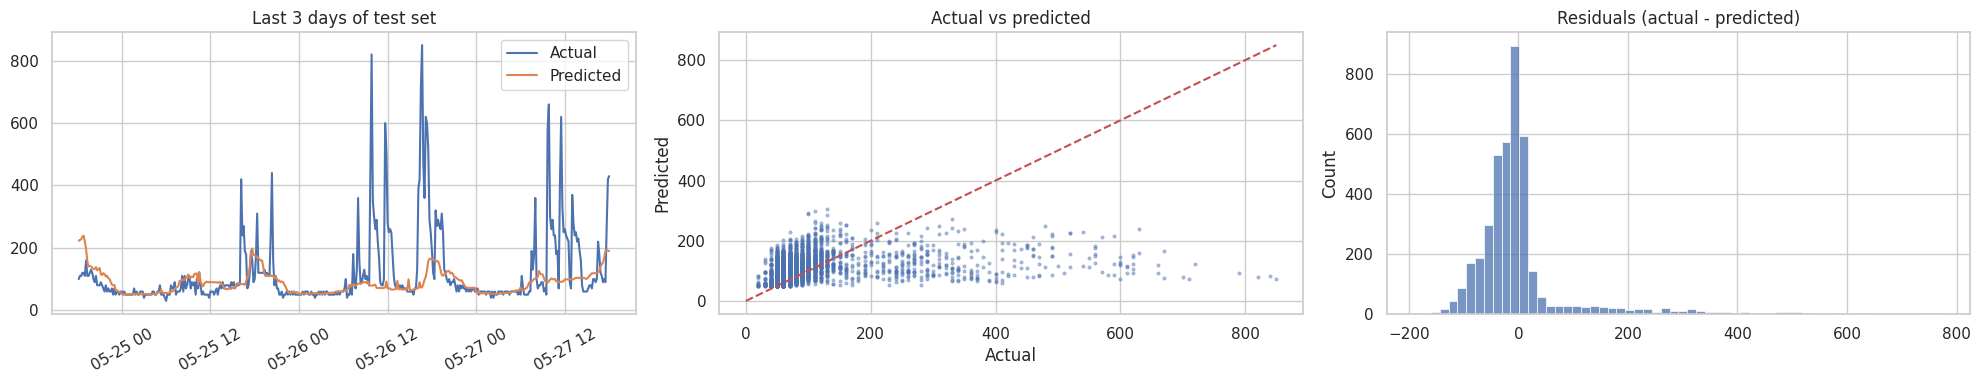

In [33]:
# Actual vs predicted on the last 3 days of the test set, and residual diagnostics
final_pred = preds["LightGBM (tuned)"]
resid = y_test.values - final_pred

n = 3 * 144  # 144 ten-minute readings per day
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
ax[0].plot(dates_test.values[-n:], y_test.values[-n:], label="Actual")
ax[0].plot(dates_test.values[-n:], final_pred[-n:], label="Predicted")
ax[0].legend(); ax[0].set_title("Last 3 days of test set"); ax[0].tick_params(axis="x", rotation=30)

ax[1].scatter(y_test, final_pred, s=4, alpha=.4)
lim = [0, max(y_test.max(), final_pred.max())]
ax[1].plot(lim, lim, "r--"); ax[1].set_xlabel("Actual"); ax[1].set_ylabel("Predicted"); ax[1].set_title("Actual vs predicted")

sns.histplot(resid, bins=60, ax=ax[2]); ax[2].set_title("Residuals (actual - predicted)")
plt.tight_layout(); plt.show()

In [34]:
# Where does the model fail? Error by consumption level
bins = pd.cut(y_test, [0, 50, 100, 200, 400, 1100])
by_level = pd.DataFrame({"abs_err": np.abs(resid), "bin": bins.values}).groupby("bin").agg(
    n=("abs_err", "size"), MAE=("abs_err", "mean"))
by_level.round(1)

,n,MAE
bin,,
"(0, 50]",1092,27.5
"(50, 100]",2028,30.9
"(100, 200]",502,39.9
"(200, 400]",234,161.8
"(400, 1100]",91,396.5


### 8.1 Overfitting check: train versus test error

In [35]:
check_models = {
    "Ridge": fitted["Ridge"],
    "Ridge (tuned)": ridge_search.best_estimator_,
    "Random Forest": fitted["Random Forest"],
    "Random Forest (tuned)": rf_search.best_estimator_,
    "LightGBM": fitted["LightGBM"],
    "LightGBM (tuned)": best_lgbm,
    f"AutoML ({automl.best_estimator})": automl,
}
of_rows = []
for name, m in check_models.items():
    tr_err, te_err = rmse(y_train, m.predict(X_train)), rmse(y_test, m.predict(X_test))
    of_rows.append({"model": name, "train_RMSE": tr_err, "test_RMSE": te_err, "test_over_train": te_err / tr_err})
pd.DataFrame(of_rows).set_index("model").round(3)

,train_RMSE,test_RMSE,test_over_train
model,,,
Ridge,96.983,87.366,0.901
Ridge (tuned),98.870,87.777,0.888
Random Forest,40.925,109.943,2.686
Random Forest (tuned),89.467,84.513,0.945
LightGBM,51.021,95.567,1.873
LightGBM (tuned),68.204,86.807,1.273
AutoML (extra_tree),95.332,85.447,0.896


Models were evaluated using RMSE, MAE, and R² on a chronological test set of 3,947 observations.

The tuned Random Forest achieved the lowest Track A RMSE of 84.513 Wh, while AutoML Extra Trees achieved the lowest MAE of 43.867 Wh. Both performed better than the mean and hour-of-day baselines on both error metrics.

However, their R² scores of 0.138 and 0.119 indicate that the models explain only a modest proportion of consumption variation. High-consumption readings were particularly difficult to predict.

## 9. Explainable AI

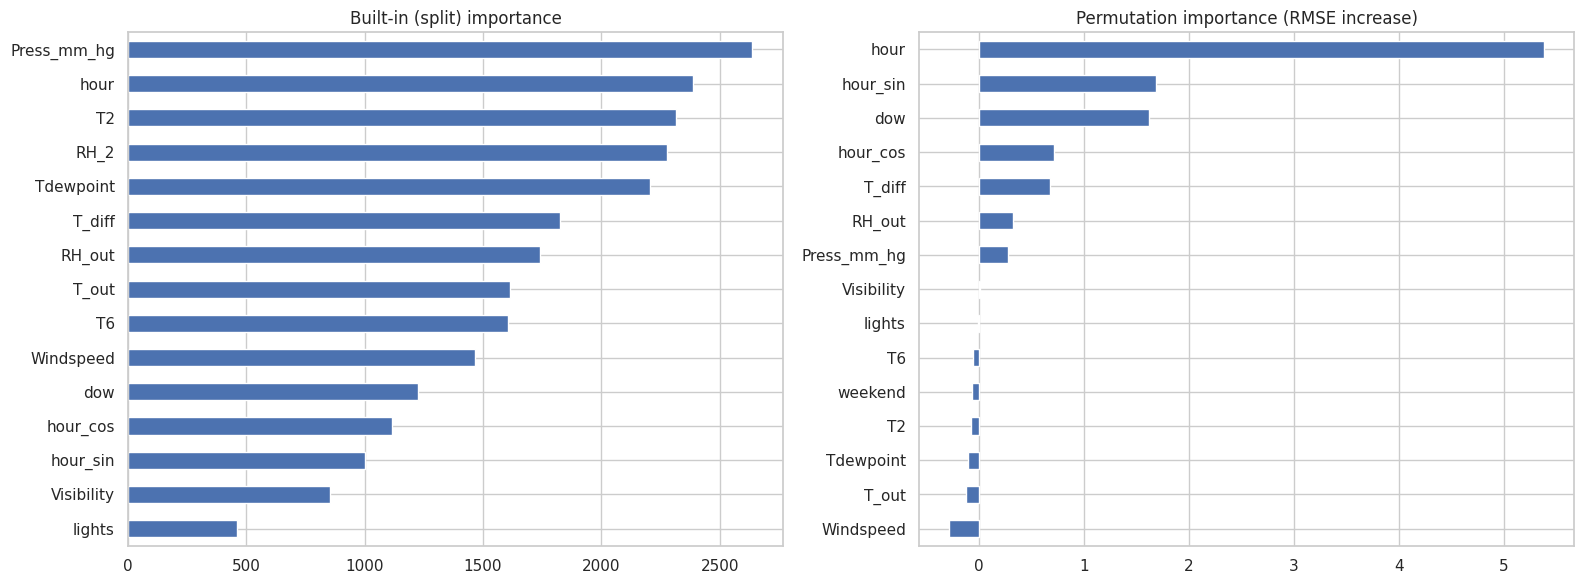

In [36]:
fi = pd.Series(best_lgbm.feature_importances_, index=X.columns).sort_values(ascending=False)
perm = permutation_importance(best_lgbm, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fi.head(15)[::-1].plot(kind="barh", ax=ax[0], title="Built-in (split) importance")
perm_s.head(15)[::-1].plot(kind="barh", ax=ax[1], title="Permutation importance (RMSE increase)")
plt.tight_layout(); plt.show()

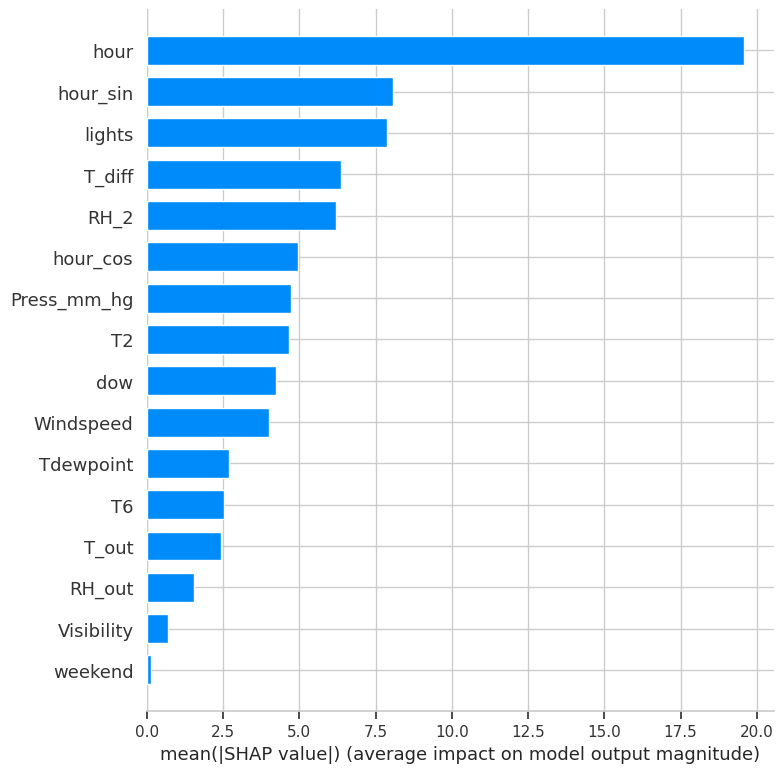

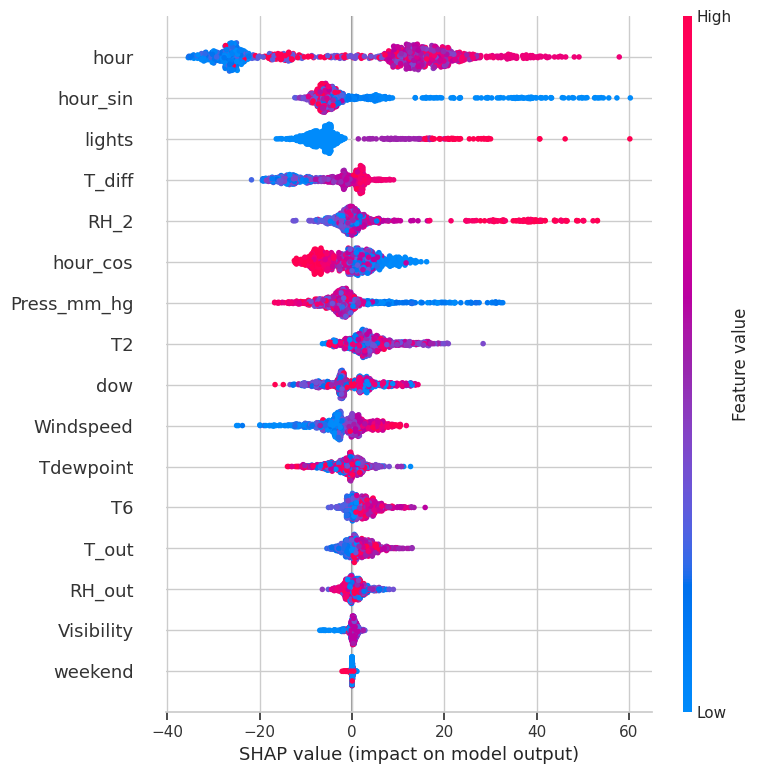

In [37]:
import shap

sample = X_test.sample(1000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(best_lgbm)
sv = explainer.shap_values(sample)

shap.summary_plot(sv, sample, plot_type="bar", show=True)
shap.summary_plot(sv, sample, show=True)

Time: 2016-05-26 16:40:00 | Actual: 850 | Predicted: 73.8


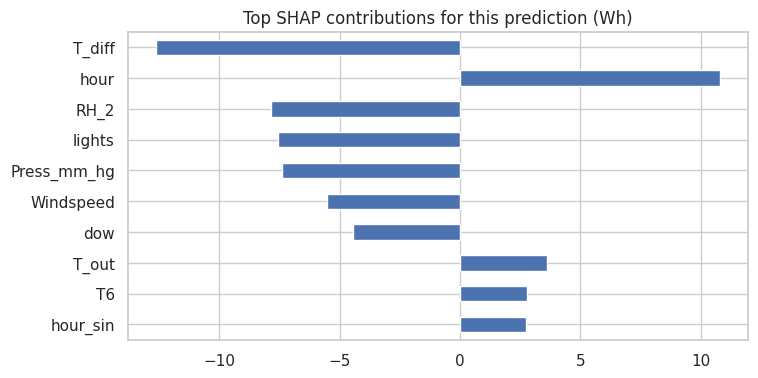

In [38]:
# Explain one high-consumption prediction locally
idx = int(np.argmax(y_test.values))
row = X_test.iloc[[idx]]
sv_row = explainer.shap_values(row)
print("Time:", dates_test.iloc[idx], "| Actual:", y_test.iloc[idx], "| Predicted:", round(float(best_lgbm.predict(row)[0]), 1))

contrib = pd.Series(sv_row[0], index=X.columns).sort_values(key=abs, ascending=False).head(10)
contrib[::-1].plot(kind="barh", figsize=(8, 4), title="Top SHAP contributions for this prediction (Wh)")
plt.show()

Highest-consumption reading | time: 2016-05-26 16:40:00 | actual: 850 | predicted: 73.8


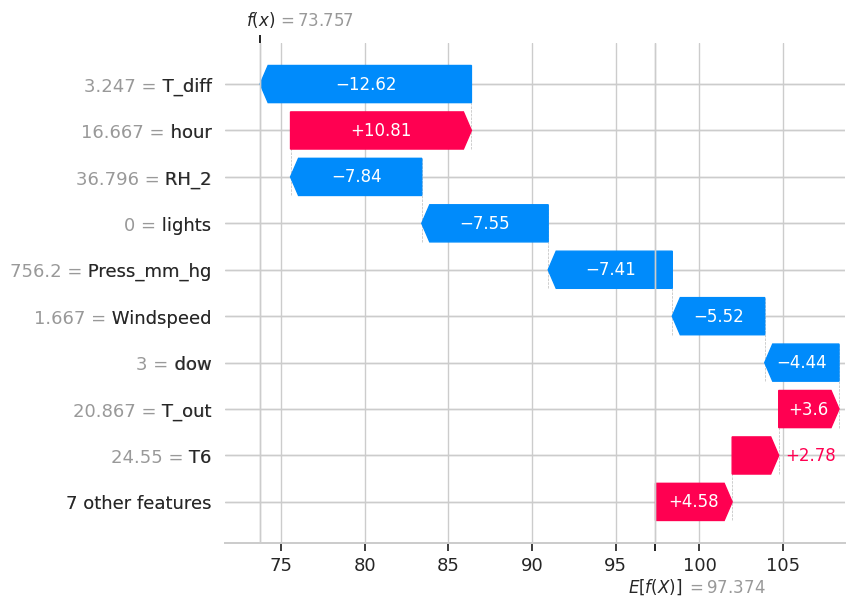

Typical (median) reading | time: 2016-05-01 00:10:00 | actual: 60 | predicted: 50.6


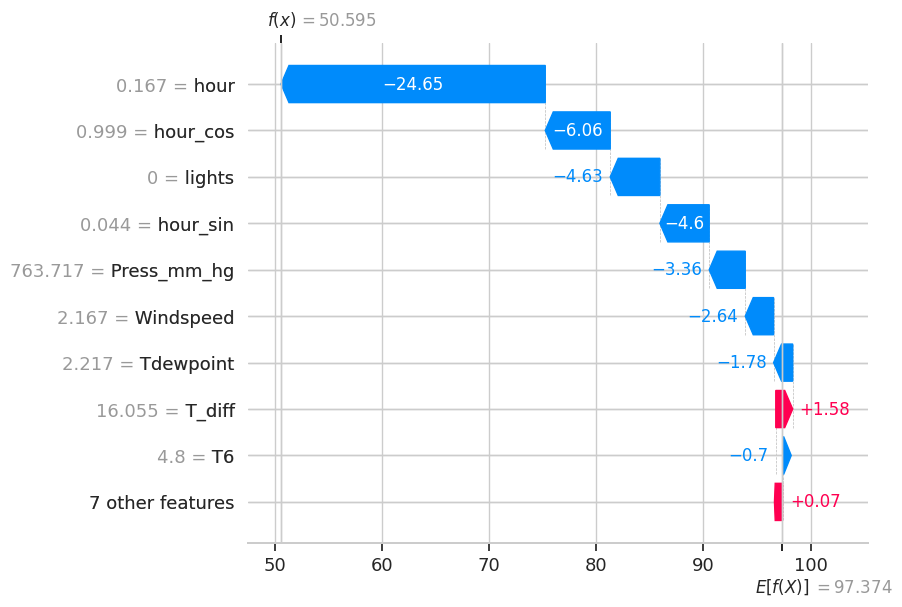

In [39]:
base_val = float(np.atleast_1d(explainer.expected_value)[0])

def waterfall_for(pos, title):
    r = X_test.iloc[[pos]]
    s = explainer.shap_values(r)[0]
    expl = shap.Explanation(values=s, base_values=base_val, data=r.iloc[0].values,
                            feature_names=list(X_test.columns))
    print(title, "| time:", dates_test.iloc[pos], "| actual:", y_test.iloc[pos],
          "| predicted:", round(float(best_lgbm.predict(r)[0]), 1))
    shap.plots.waterfall(expl, max_display=10, show=True)

waterfall_for(int(np.argmax(y_test.values)), "Highest-consumption reading")
waterfall_for(int(np.argsort(y_test.values)[len(y_test) // 2]), "Typical (median) reading")

### 9.2 How one feature changes predictions, and cross-checking the methods

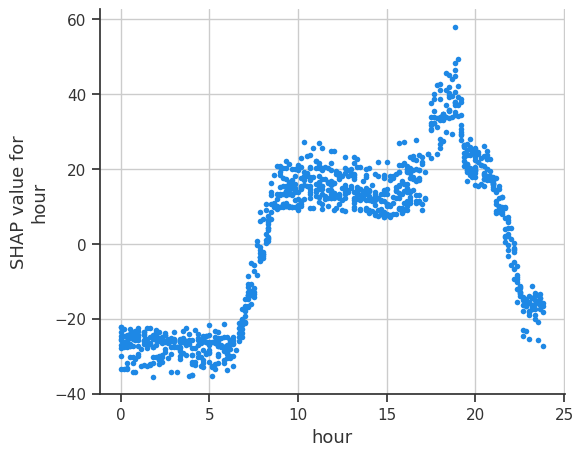

Top 10 features by SHAP, with the rank each method gives them (1 = most important):


,split_importance,permutation,mean_abs_SHAP,ridge_abs_coef
hour,2.0,1.0,1.0,4.0
hour_sin,13.0,2.0,2.0,3.0
lights,15.0,9.0,3.0,2.0
T_diff,6.0,5.0,4.0,11.0
RH_2,4.0,16.0,5.0,16.0
hour_cos,12.0,4.0,6.0,1.0
Press_mm_hg,1.0,7.0,7.0,8.0
T2,3.0,12.0,8.0,5.0
dow,11.0,3.0,9.0,12.0
Windspeed,10.0,15.0,10.0,9.0


Spearman rank agreement between methods:


,split_importance,permutation,mean_abs_SHAP,ridge_abs_coef
split_importance,1.00,-0.08,0.28,0.00
permutation,-0.08,1.00,0.43,0.49
mean_abs_SHAP,0.28,0.43,1.00,0.53
ridge_abs_coef,0.00,0.49,0.53,1.00


In [40]:
if "hour" in sample.columns:
    shap.dependence_plot("hour", sv, sample, interaction_index=None)

mean_abs_shap = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns)
ridge_coef = pd.Series(np.abs(ridge_search.best_estimator_.named_steps["ridge"].coef_),
                       index=scale_cols + pass_cols)
xai = pd.DataFrame({"split_importance": fi, "permutation": perm_s,
                    "mean_abs_SHAP": mean_abs_shap, "ridge_abs_coef": ridge_coef}).reindex(X_test.columns)
ranks = xai.rank(ascending=False)
print("Top 10 features by SHAP, with the rank each method gives them (1 = most important):")
display(ranks.sort_values("mean_abs_SHAP").head(10).round(0))
print("Spearman rank agreement between methods:")
display(ranks.corr(method="spearman").round(2))

Feature importance, permutation importance, SHAP, and Ridge coefficients were used to understand model predictions.

The SHAP analysis identified hour, hour_sin, lights, T_diff, and RH_2 among the most important features. These results suggest that time patterns, lighting, and environmental measurements contribute to predictions.

The importance methods did not fully agree, indicating that feature rankings depend on the explanation technique. These results describe model behaviour and do not establish causation.

## 10. Unusual observations: anomalies are not waste

In [41]:
med = np.median(resid)
mad = np.median(np.abs(resid - med))
rz = 0.6745 * (resid - med) / mad
resid_flag = np.abs(rz) > 3.5

iso = IsolationForest(contamination=0.02, random_state=RANDOM_STATE)
iso_flag = iso.fit_predict(StandardScaler().fit_transform(X_all.iloc[split:])) == -1

flags = pd.DataFrame({
    "date": dates_test.values, "actual": y_test.values, "predicted": final_pred.round(1),
    "residual": resid.round(1), "robust_z": rz.round(2),
    "residual_flag": resid_flag, "unusual_conditions_flag": iso_flag,
})

print("Residual-flagged:", resid_flag.sum(), f"({resid_flag.mean():.1%})")
print("Isolation-Forest-flagged:", iso_flag.sum(), f"({iso_flag.mean():.1%})")
print("\nOverlap:")
display(pd.crosstab(flags["residual_flag"], flags["unusual_conditions_flag"]))

Residual-flagged: 313 (7.9%)
Isolation-Forest-flagged: 79 (2.0%)

Overlap:


unusual_conditions_flag,False,True
residual_flag,,
False,3575,59
True,293,20


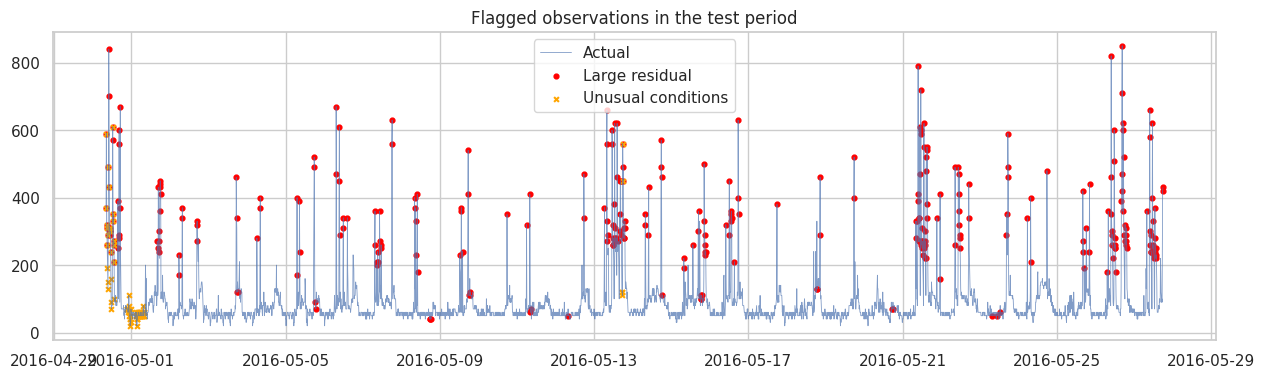

,date,actual,predicted,residual,robust_z,residual_flag,unusual_conditions_flag
3794,2016-05-26 16:40:00,850,73.8,776.2,24.68,True,False
10,2016-04-30 10:00:00,840,82.5,757.5,24.09,True,False
3753,2016-05-26 09:50:00,820,79.2,740.8,23.57,True,False
3032,2016-05-21 09:40:00,790,93.7,696.3,22.18,True,False
3793,2016-05-26 16:30:00,710,72.6,637.4,20.33,True,False
11,2016-04-30 10:10:00,700,79.1,620.9,19.82,True,False
3042,2016-05-21 11:20:00,720,122.4,597.6,19.09,True,False
859,2016-05-06 07:30:00,670,76.1,593.9,18.97,True,False
3897,2016-05-27 09:50:00,660,93.2,566.8,18.13,True,False
1870,2016-05-13 08:00:00,660,118.0,542.0,17.35,True,False


In [42]:
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(flags["date"], flags["actual"], lw=.6, label="Actual", alpha=.7)
ax.scatter(flags.loc[flags.residual_flag, "date"], flags.loc[flags.residual_flag, "actual"],
           color="red", s=12, label="Large residual")
ax.scatter(flags.loc[flags.unusual_conditions_flag, "date"], flags.loc[flags.unusual_conditions_flag, "actual"],
           color="orange", s=12, marker="x", label="Unusual conditions")
ax.legend(); ax.set_title("Flagged observations in the test period"); plt.show()

flags.loc[flags.residual_flag].sort_values("robust_z", key=abs, ascending=False).head(10)

Two methods were used to identify unusual observations: robust residual scoring and Isolation Forest.

The residual method flagged 313 readings (7.9%), while Isolation Forest flagged 79 readings (2.0%). Only 20 observations were flagged by both methods.

One notable reading occurred on 26 May 2016 at 16:40, when actual consumption was 850 Wh but the tuned LightGBM predicted 73.8 Wh. Anomalies indicate observations that deserve investigation; they do not automatically represent energy waste.

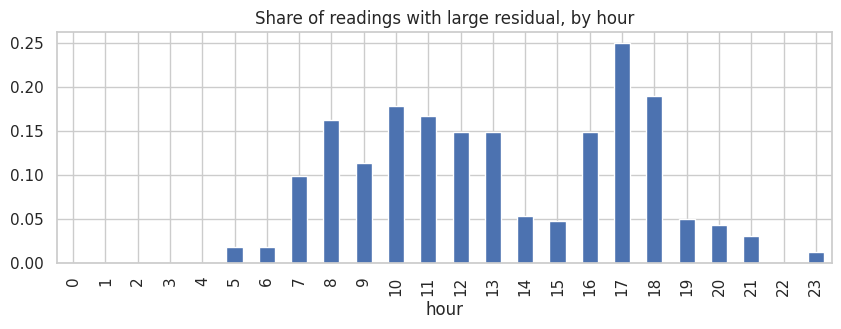

In [43]:
# When do the flagged residuals happen? (context, not proof of anything)
fl = flags.copy()
fl["hour"] = pd.to_datetime(fl["date"]).dt.hour
fl.groupby("hour")["residual_flag"].mean().plot(kind="bar", figsize=(10, 3),
    title="Share of readings with large residual, by hour")
plt.show()

In [44]:
lag_src = data["Appliances"]
lags = pd.DataFrame({
    "lag1": lag_src.shift(1),
    "lag6_mean": lag_src.shift(1).rolling(6).mean(),
    "lag36_mean": lag_src.shift(1).rolling(36).mean(),
})
LAG_COLS = list(lags.columns)
XB = pd.concat([X_all[FEATURES], lags], axis=1)

# The first 36 training rows have no full history; the test rows are the same as in sections 5-10
train_ok = XB.iloc[:split].notna().all(axis=1).values
XB_train, yB_train = XB.iloc[:split][train_ok], y.iloc[:split][train_ok]
XB_test, yB_test = XB.iloc[split:], y.iloc[split:]
assert not XB_test.isna().any().any()
assert len(XB_test) == len(X_test)

# Leakage check: lag1 on row t is the target of row t-1, never of row t
assert np.allclose(XB_test["lag1"].values[1:], yB_test.values[:-1])
print("Track B features:", XB.shape[1], "(", len(FEATURES), "stable +", len(LAG_COLS), "past-only )")
print("Training rows:", len(XB_train), "| test rows:", len(XB_test))

Track B features: 19 ( 16 stable + 3 past-only )
Training rows: 15752 | test rows: 3947


In [45]:
pass_B = [c for c in ["weekend", "hour_sin", "hour_cos"] if c in XB_train.columns]
scale_B = [c for c in XB_train.columns if c not in pass_B]

def make_prep_B():
    return ColumnTransformer([
        ("scale", Pipeline([("impute", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), scale_B),
        ("keep", "passthrough", pass_B),
    ])

rows_B = []
def add_B(name, p, cv=np.nan):
    rows_B.append({"model": name, "cv_rmse": cv, "RMSE": rmse(yB_test, p),
                   "MAE": mean_absolute_error(yB_test, p), "R2": r2_score(yB_test, p)})

# Baselines
add_B("Mean baseline", np.full(len(yB_test), yB_train.mean()))
add_B("Persistence (previous reading)", XB_test["lag1"].values)
add_B("Previous-hour mean", XB_test["lag6_mean"].values)

# Ridge, alpha tuned with time-ordered CV on the training period
ridge_B = GridSearchCV(Pipeline([("prep", make_prep_B()), ("ridge", Ridge())]),
                       {"ridge__alpha": [0.1, 1, 10, 100, 1000, 10000]},
                       cv=TimeSeriesSplit(n_splits=4), scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_B.fit(XB_train, yB_train)
print("Ridge (B) best:", ridge_B.best_params_, "| CV RMSE:", round(-ridge_B.best_score_, 3))
add_B("Ridge (tuned)", ridge_B.predict(XB_test), -ridge_B.best_score_)

# LightGBM, tuned with the same search space as section 7
search_B = RandomizedSearchCV(LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),
                              param_distributions=param_dist, n_iter=15,
                              cv=TimeSeriesSplit(n_splits=4), scoring="neg_root_mean_squared_error",
                              random_state=RANDOM_STATE, n_jobs=-1)
search_B.fit(XB_train, yB_train)
best_lgbm_B = search_B.best_estimator_
print("LightGBM (B) best:", search_B.best_params_, "| CV RMSE:", round(-search_B.best_score_, 3))
add_B("LightGBM (tuned)", best_lgbm_B.predict(XB_test), -search_B.best_score_)

resB = pd.DataFrame(rows_B).set_index("model").sort_values("RMSE")
test_mean_B = float(yB_test.mean())
resB["typical_error_%_of_avg_use"] = 100 * resB["MAE"] / test_mean_B
resB["variance_explained_%"] = 100 * resB["R2"]
resB.round(3)

Ridge (B) best: {'ridge__alpha': 100} | CV RMSE: 66.811
LightGBM (B) best: {'subsample_freq': 1, 'subsample': 0.8, 'reg_lambda': 10, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 80, 'learning_rate': 0.02, 'colsample_bytree': 0.8} | CV RMSE: 65.153


,cv_rmse,RMSE,MAE,R2,typical_error_%_of_avg_use,variance_explained_%
model,,,,,,
LightGBM (tuned),65.153,60.226,27.097,0.562,28.115,56.236
Ridge (tuned),66.811,61.156,26.301,0.549,27.289,54.873
Persistence (previous reading),NaN,66.438,26.651,0.467,27.652,46.743
Previous-hour mean,NaN,75.528,34.296,0.312,35.585,31.172
Mean baseline,NaN,91.051,52.629,-0.000,54.607,-0.028


In [46]:
# Criterion: beat persistence and the previous-hour mean on RMSE and MAE, with R2 > 0
pers, hr1 = resB.loc["Persistence (previous reading)"], resB.loc["Previous-hour mean"]
chk = resB.drop(index=["Mean baseline", "Persistence (previous reading)", "Previous-hour mean"]).copy()
chk["beats_persistence"] = (chk["RMSE"] < pers["RMSE"]) & (chk["MAE"] < pers["MAE"])
chk["beats_prev_hour_mean"] = (chk["RMSE"] < hr1["RMSE"]) & (chk["MAE"] < hr1["MAE"])
chk["R2_above_0"] = chk["R2"] > 0
chk[["RMSE", "MAE", "R2", "beats_persistence", "beats_prev_hour_mean", "R2_above_0"]].round(3)

,RMSE,MAE,R2,beats_persistence,beats_prev_hour_mean,R2_above_0
model,,,,,,
LightGBM (tuned),60.226,27.097,0.562,False,True,True
Ridge (tuned),61.156,26.301,0.549,True,True,True


In [47]:
# Error by consumption level for the tuned LightGBM (track B)
pB = best_lgbm_B.predict(XB_test)
errB = np.abs(yB_test.values - pB)
bins = pd.cut(yB_test, [0, 50, 100, 200, 400, 1100])
pd.DataFrame({"abs_err": errB, "bin": bins.values}).groupby("bin").agg(n=("abs_err", "size"), MAE=("abs_err", "mean")).round(1)

,n,MAE
bin,,
"(0, 50]",1092,9.8
"(50, 100]",2028,16.5
"(100, 200]",502,40.5
"(200, 400]",234,87.8
"(400, 1100]",91,239.7


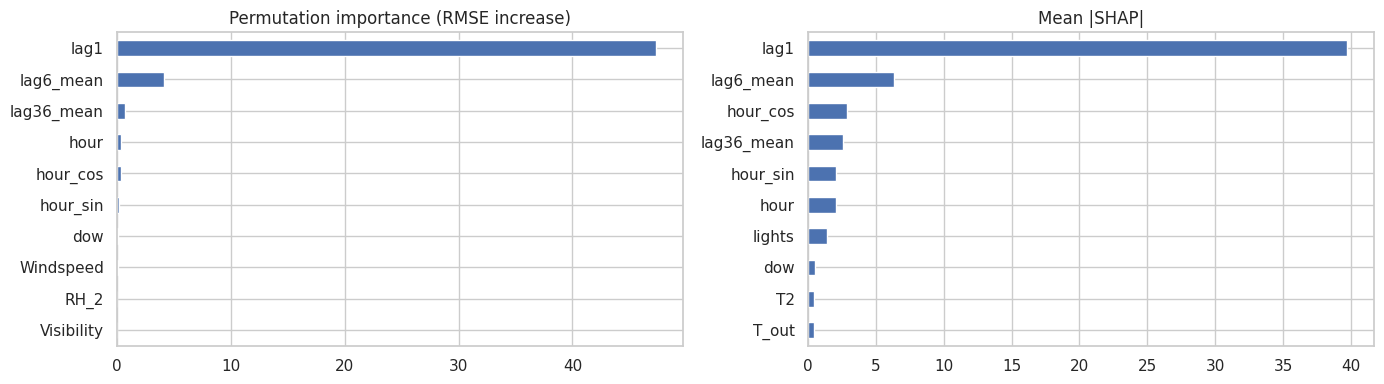

Top 5 by permutation: {'lag1': 47.35, 'lag6_mean': 4.15, 'lag36_mean': 0.68, 'hour': 0.37, 'hour_cos': 0.35}
Top 5 by SHAP      : {'lag1': 39.72, 'lag6_mean': 6.35, 'hour_cos': 2.88, 'lag36_mean': 2.61, 'hour_sin': 2.05}


In [48]:
# What does the track-B model use? Permutation importance (test) and SHAP
permB = permutation_importance(best_lgbm_B, XB_test, yB_test, n_repeats=5, random_state=RANDOM_STATE,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
permB_s = pd.Series(permB.importances_mean, index=XB.columns).sort_values(ascending=False)

sampleB = XB_test.sample(1000, random_state=RANDOM_STATE)
svB = shap.TreeExplainer(best_lgbm_B).shap_values(sampleB)
shapB = pd.Series(np.abs(svB).mean(axis=0), index=sampleB.columns).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
permB_s.head(10)[::-1].plot(kind="barh", ax=ax[0], title="Permutation importance (RMSE increase)")
shapB.head(10)[::-1].plot(kind="barh", ax=ax[1], title="Mean |SHAP|")
plt.tight_layout(); plt.show()
print("Top 5 by permutation:", permB_s.head(5).round(2).to_dict())
print("Top 5 by SHAP      :", shapB.head(5).round(2).to_dict())

In [49]:
# Both tracks side by side, in Wh and in percent
test_mean = float(y_test.mean())
final = pd.concat({
    "A: conditions only": res_df.loc[["Mean baseline", "Hour-of-day baseline", "Ridge (tuned)", "LightGBM (tuned)"], ["RMSE", "MAE", "R2"]],
    "B: + recent consumption": resB.loc[["Persistence (previous reading)", "Previous-hour mean", "Ridge (tuned)", "LightGBM (tuned)"], ["RMSE", "MAE", "R2"]],
})
final["typical_error_%_of_avg_use"] = (100 * final["MAE"] / test_mean).round(0)
final["variance_explained_%"] = (100 * final["R2"]).round(0)
final.round(3)

RMSE     MAE     R2  \
                        model                                                   
A: conditions only      Mean baseline                   91.053  52.685 -0.000   
                        Hour-of-day baseline            85.482  46.947  0.118   
                        Ridge (tuned)                   87.777  52.865  0.070   
                        LightGBM (tuned)                86.807  47.315  0.091   
B: + recent consumption Persistence (previous reading)  66.438  26.651  0.467   
                        Previous-hour mean              75.528  34.296  0.312   
                        Ridge (tuned)                   61.156  26.301  0.549   
                        LightGBM (tuned)                60.226  27.097  0.562   

                                                        typical_error_%_of_avg_use  \
                        model                                                        
A: conditions only      Mean baseline                                         55.0   
                        Hour-of-day baseline                                  49.0   
                        Ridge (tuned)                                         55.0   
                        LightGBM (tuned)                                      49.0   
B: + recent consumption Persistence (previous reading)                        28.0   
                        Previous-hour mean                                    36.0   
                        Ridge (tuned)                                         27.0   
                        LightGBM (tuned)                                      28.0   

                                                        variance_explained_%  
                        model                                                 
A: conditions only      Mean baseline                                   -0.0  
                        Hour-of-day baseline                            12.0  
                        Ridge (tuned)                                    7.0  
                        LightGBM (tuned)                                 9.0  
B: + recent consumption Persistence (previous reading)                  47.0  
                        Previous-hour mean                              31.0  
                        Ridge (tuned)                                   55.0  
                        LightGBM (tuned)                                56.0

Track B added three past-consumption features: lag1, lag6_mean, and lag36_mean. These represent the previous reading and rolling averages of recent readings.

Tuned LightGBM achieved the best RMSE (60.226 Wh) and R² (0.562). Tuned Ridge achieved an RMSE of 61.156 Wh, MAE of 26.301 Wh, and R² of 0.549.

Although LightGBM had the lowest RMSE, Ridge was the model that improved on the persistence baseline in both RMSE and MAE. Recent consumption, especially lag1, was the strongest predictor. Track B forecasts 10 minutes ahead and requires recent readings to be available.

## 12. Findings, reflection and presentation script

The results show that predicting appliance energy consumption using environmental and time-based features alone is challenging. Tuned Random Forest performed best by RMSE in Track A, while AutoML Extra Trees achieved the lowest MAE.

Adding recent consumption readings substantially improved short-term forecasting. Tuned LightGBM achieved the best RMSE in Track B, but tuned Ridge was the model that beat persistence on both RMSE and MAE.

Feature engineering, model tuning, and explainability helped evaluate model performance and understand prediction behaviour. Nevertheless, peak consumption remained difficult to predict, and anomaly detection could not determine whether unusual readings represented waste.

Overall, the project demonstrates the value of machine learning for short-term energy prediction while highlighting the limitations of a dataset covering one house and one test period. Further testing on additional homes and time periods would be needed to assess generalisability.